## 📈 Predicting Football League Final Positions Using Betting Odds, Probabilistic Modelling & Simulation
### *(Masterclass Edition — 2026/27 Season Refresh, with a Rugby Annex)*

**Competitions:** Premier League, Championship, Serie A, La Liga, Bundesliga, Ligue 1, Eredivisie, Primeira Liga, Brazil Serie A — 2026/27 season\
**Purpose:** Estimate probabilities of final league positions using betting market information, a Poisson goal model, and simulation\
**Methods:** Odds-implied probabilities, Poisson goal modelling, empirical-Bayes-style shrinkage, Monte Carlo simulation\
**Author:** [Victoria Friss de Kereki](https://www.linkedin.com/in/victoria-friss-de-kereki/)\
**Live results (updated daily, all 9 leagues):** [football-league-simulator.streamlit.app](https://football-league-simulator.streamlit.app/)\
**Companion notebook:** `202608 - 1 - Priors for Promoted and Relegated Teams.ipynb` (the promoted/relegated evidence behind Section 6)\
**Consolidates:**\
[Predicting Premier League Final Positions Using Betting Odds, Probabilistic Modelling & Simulation](https://medium.com/p/2720ec335c3c)\
[Building a Probabilistic Premier League Simulator in Python](https://medium.com/@vickyfrissdekereki/building-a-probabilistic-premier-league-simulator-in-python-34b5248f81b9)\
[Predicting English Rugby Premiership Final Positions Using Probabilistic Modelling & Simulation](https://medium.com/@vickyfrissdekereki/predicting-english-rugby-premiership-final-positions-using-probabilistic-modelling-simulation-353a7810be10) (see the annex)

---

**Original notebook first written:** `17/01/2026`\
**This masterclass edition assembled:** `01/08/2026`\
**Last updated:** `19/10/2026`\
**Masterclass date:** `19/10/2026` (Training Ground Guru)

> This notebook is the "everything I know so far" version of the football simulator: it folds the production-hardened pipeline (`1_dataset_creation.py` → `4_simulations.py` in the `football-league-predictions` repo) back into a single narrative notebook, ready to run fresh for the 2026/27 season.
>
> The modelling core hasn't changed since the original write-up: betting odds are turned into de-vigged implied probabilities, a Poisson model estimates each team's attack/defence strength from historical goals, and the two are combined and simulated thousands of times to build a full distribution over final league positions.
>
> What *is* new in this edition: per-team early-season shrinkage, evidence-based targets for promoted and relegated teams (Section 6), and a deliberately "science-based" framing around every step — the assumptions each technique makes, why it can break, and what a more rigorous version would look like — because the point of this notebook is to teach the *reasoning*, not just hand over working code. It closes with a discussion of the model's biggest weakness (goals are a slow, noisy signal) and how tracking data of the kind SkillCorner produces could sharpen it, plus an annex on why this exact recipe does **not** transfer cleanly to rugby.
>
> Throughout, the deliverable is always a **distribution**, never a headline prediction. The model never says "Arsenal will finish first" — it says "Arsenal has a 34% chance of finishing first, 27% of finishing second, …". That distinction is the single most important idea in this notebook.




### How this notebook is organised

0. Setup & season configuration
1. League standings (starting point / boundary condition for the simulation)
2. Betting odds → de-vigged market probabilities
3. Remaining fixtures
4. Historical results (this season + prior seasons)
5. Data integrity safeguards (the unglamorous 80%)
6. Team strength ratings: Poisson attack/defence + early-season shrinkage
7. Match outcome probabilities: the market where it has a price, the model elsewhere
8. Monte Carlo simulation of the rest of the season
9. Results: full position-probability tables
10. Validating the model against the market
11. From notebook to production: the daily-refresh pipeline
12. Discussion: talking in probabilities, and where tracking data could take this further
13. **Annex — Predicting rugby: why football's simplicity doesn't transfer**


## 0. Setup & season configuration

Everything below is parameterised per-league from the start. The original notebook was written for a single competition (the Premier League); the production pipeline that grew out of it runs nine leagues off the same code path. There's no statistical reason to special-case one league — the only per-league things that matter are the season start date and the API/scraper codes, so those are pulled into one config block up front instead of being hard-coded deeper in the logic.


In [1]:
# Core
from datetime import datetime, timedelta, timezone
from io import StringIO
import os
import time

# Data manipulation
import numpy as np
import pandas as pd

# APIs & environment
import requests
from dotenv import load_dotenv

# Statistics
from scipy.stats import poisson

# Visualisation
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, HTML


In [2]:
# -------------------------------
# Season configuration — the only block that should need editing each season
# -------------------------------

SEASON_YEAR = 2026  # update every August when a new season kicks off

# ESPN standings scraper codes -> (internal league name, season year for the ESPN URL)
ESPN_LEAGUE_CODES = {
    "ENG.1": ("premierleague_england", SEASON_YEAR),
    "ENG.2": ("championship_england", SEASON_YEAR),
    "ITA.1": ("seriea_italy", SEASON_YEAR),
    "ESP.1": ("laliga_spain", SEASON_YEAR),
    "GER.1": ("bundesliga_germany", SEASON_YEAR),
    "FRA.1": ("ligue1_france", SEASON_YEAR),
    "NED.1": ("eredivisie_netherlands", SEASON_YEAR),
    "BRA.1": ("seriea_brazil", SEASON_YEAR),  # Brasileirao runs Jan-Dec, but ESPN/football-data.org still label
    # that calendar year with the SAME season number Aug-May leagues use for their start year -- NOT one
    # year ahead. The very first live run of this notebook broke here: SEASON_YEAR + 1 requested ESPN's
    # /season/2027 page for a season that will not exist for another year, got back a page with no table
    # at all, and pd.read_html raised "No tables found". Only the START DATE differs (Jan 1 instead of
    # Aug 1, below) -- the year-numbering convention does not.
    "POR.1": ("primeiraliga_portugal", SEASON_YEAR),  # added once La Liga (but not yet the Premier League)
    # had actually kicked off -- see the write-up above for how this one was picked.
}

# the-odds-api.com sport keys -> internal league name
ODDS_API_LEAGUES = {
    "soccer_epl": "odds_premierleague_england",
    "soccer_efl_champ": "odds_championship_england",
    "soccer_italy_serie_a": "odds_seriea_italy",
    "soccer_spain_la_liga": "odds_laliga_spain",
    "soccer_germany_bundesliga": "odds_bundesliga_germany",
    "soccer_france_ligue_one": "odds_ligue1_france",
    "soccer_netherlands_eredivisie": "odds_eredivisie_netherlands",
    "soccer_brazil_campeonato": "odds_seriea_brazil",
    "soccer_portugal_primeira_liga": "odds_primeiraliga_portugal",
}

# football-data.org competition codes -> internal league name
FOOTBALL_DATA_COMPETITIONS = {
    "PL": "premierleague_england",
    "ELC": "championship_england",
    "SA": "seriea_italy",
    "PD": "laliga_spain",
    "BL1": "bundesliga_germany",
    "FL1": "ligue1_france",
    "DED": "eredivisie_netherlands",
    "BSA": "seriea_brazil",
    "PPL": "primeiraliga_portugal",
}

leagues = list(FOOTBALL_DATA_COMPETITIONS.values())

# Season start dates — used to slice "this season" out of the combined past-matches history
SEASON_START_DATES = {
    "premierleague_england": pd.Timestamp(f"{SEASON_YEAR}-08-01", tz="UTC"),
    "championship_england": pd.Timestamp(f"{SEASON_YEAR}-08-01", tz="UTC"),
    "seriea_italy": pd.Timestamp(f"{SEASON_YEAR}-08-01", tz="UTC"),
    "laliga_spain": pd.Timestamp(f"{SEASON_YEAR}-08-01", tz="UTC"),
    "bundesliga_germany": pd.Timestamp(f"{SEASON_YEAR}-08-01", tz="UTC"),
    "ligue1_france": pd.Timestamp(f"{SEASON_YEAR}-08-01", tz="UTC"),
    "eredivisie_netherlands": pd.Timestamp(f"{SEASON_YEAR}-08-01", tz="UTC"),
    "seriea_brazil": pd.Timestamp(f"{SEASON_YEAR}-01-01", tz="UTC"),  # same SEASON_YEAR, different month
    "primeiraliga_portugal": pd.Timestamp(f"{SEASON_YEAR}-08-01", tz="UTC"),
}

# Past seasons to blend in as prior information, per league: [current, previous]
PAST_SEASONS = {
    "premierleague_england": [SEASON_YEAR, SEASON_YEAR - 1],
    "championship_england": [SEASON_YEAR, SEASON_YEAR - 1],
    "seriea_italy": [SEASON_YEAR, SEASON_YEAR - 1],
    "laliga_spain": [SEASON_YEAR, SEASON_YEAR - 1],
    "bundesliga_germany": [SEASON_YEAR, SEASON_YEAR - 1],
    "ligue1_france": [SEASON_YEAR, SEASON_YEAR - 1],
    "eredivisie_netherlands": [SEASON_YEAR, SEASON_YEAR - 1],
    "seriea_brazil": [SEASON_YEAR, SEASON_YEAR - 1],
    "primeiraliga_portugal": [SEASON_YEAR, SEASON_YEAR - 1],
}

print(f"Configured for the {SEASON_YEAR}/{str(SEASON_YEAR + 1)[-2:]} season across {len(leagues)} leagues.")


Configured for the 2026/27 season across 9 leagues.


In [3]:
# -------------------------------
# API keys — loaded from API_KEY.env (see README), never hard-coded
# -------------------------------

def get_api_key(env_var_name, local_file="API_KEY.env"):
    """Checks the environment first, then API_KEY.env in a few likely locations.
    This notebook lives in Football-analytics/, but the key file was created in the
    sibling football-league-predictions/ repo — a plain os.path.exists("API_KEY.env")
    only finds it if the two happen to share a folder, which they don't here."""
    key = os.getenv(env_var_name)
    if key:
        return key

    candidate_paths = [
        local_file,
        os.path.join("..", "football-league-predictions", local_file),
        os.path.join(os.path.expanduser("~"), "Documents", "GitHub", "Personal",
                     "football-league-predictions", local_file),
    ]
    for path in candidate_paths:
        if os.path.exists(path):
            load_dotenv(path)
            key = os.getenv(env_var_name)
            if key:
                return key

    raise ValueError(
        f"{env_var_name} not found in environment variables or any of: {candidate_paths}"
    )


def request_with_retry(url, headers=None, params=None, max_retries=5):
    """A plain requests.get() is fine for a one-off notebook run. It is NOT fine for something
    meant to run unattended every day for a 9-month season — rate limits, transient 5xxs and
    flaky wifi on a scheduled runner will eventually hit you. Retry with backoff costs five lines
    and turns "the pipeline silently died in March" into "it tried again a minute later"."""
    for attempt in range(1, max_retries + 1):
        try:
            response = requests.get(url, headers=headers, params=params, timeout=30)
            response.raise_for_status()
            return response
        except Exception as e:
            if attempt == max_retries:
                print(f"❌ Final attempt failed for {url}")
                raise
            wait_time = attempt * 60
            print(f"⚠️ API call failed: {e}. Retrying in {attempt} minute(s)...")
            time.sleep(wait_time)


## 1. League standings (ESPN scraping)

The current table (points, games played, goal difference) isn't part of the *probability model* at all — it's the **boundary condition** for the simulation. Everything from Section 6 onward answers "what's the chance of each result in each remaining match?"; the standings answer "and what does each team already have in the bank?". Get this wrong (stale cache, a missed postponed match) and the whole distribution shifts, even if the match-level model is perfect.

Adapted from the ESPN scraper originally built for the single-league version, now looped across all nine competitions with the same team-name-cleaning safety net (ESPN's scoreboard text is inconsistently formatted — stray codes glued to team names, `"+"` signs in goal difference, etc.).


In [4]:
TEAM_NAME_MAPPING = {
    "AAS Roma": "AS Roma",
    "OComo": "Como",
    "B04Bayer Leverkusen": "Bayer Leverkusen",
    "M05Mainz": "Mainz",
    "NLyon": "Lyon",
    "LLille": "Lille",
    "ENice": "Nice",
    "ZMetz": "Metz",
    "ORemo": "Remo",
    "Z Alkmaar": "AZ Alkmaar",
    # Primeira Liga: several clubs' ESPN codes run 4 characters (e.g. Santa Clara -> "CDSC"),
    # one more than [A-Z0-9]{2,3} strips, so a single leftover capital stays glued to the name.
    "CSanta Clara": "Santa Clara", "CGil Vicente": "Gil Vicente",
    "CRio Ave": "Rio Ave", "CCasa Pia": "Casa Pia",
}

def clean_team_names(df, column="team"):
    df = df.copy()
    df[column] = df[column].replace(TEAM_NAME_MAPPING)
    return df


def fetch_html_via_browser(url, wait_selector="table"):
    """The production fallback (see the note below): a real headless Chromium tab runs ESPN's
    WAF challenge JS and lands on the actual page, same as a human visit would. Imported here,
    on demand, so the rest of this notebook carries no hard Playwright dependency."""
    from playwright.sync_api import sync_playwright

    with sync_playwright() as p:
        browser = p.chromium.launch(headless=True)
        page = browser.new_page(
            user_agent="Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                       "(KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36"
        )
        page.goto(url, timeout=45000, wait_until="domcontentloaded")
        page.wait_for_selector(wait_selector, timeout=30000)
        html = page.content()
        browser.close()
        return html


def fetch_html(url, headers, retries=3):
    """ESPN occasionally serves a near-empty page to a blocked/rate-limited request instead of
    an honest error — checking response size, not just status code, catches that. From a normal
    residential/office IP, plain `requests` almost always gets through; if it doesn't after a few
    tries, fall back to a real browser rather than fail outright (see the note below for why)."""
    for i in range(retries):
        try:
            response = requests.get(url, headers=headers, timeout=30)
            if response.status_code == 200 and len(response.text.strip()) > 2000:
                return response.text
        except Exception as e:
            print(f"Request error: {e}")
        time.sleep(2 ** i)

    print("Plain requests didn't get a real page back — falling back to a headless browser...")
    try:
        return fetch_html_via_browser(url)
    except ImportError:
        raise RuntimeError(
            f"Failed to fetch valid HTML for {url}, and Playwright isn't installed to fall back on. "
            "Run `pip install playwright && playwright install chromium` if this keeps happening."
        )


def scrape_standings(espn_league_codes):
    headers = {
        "User-Agent": "Mozilla/5.0",
        "Accept-Language": "en-US,en;q=0.9",
    }

    standings = {}

    for league_code, (df_name, year) in espn_league_codes.items():
        url = f"https://www.espn.com/soccer/standings/_/league/{league_code}/season/{year}"
        html = fetch_html(url, headers)

        tables = pd.read_html(StringIO(html))
        teams_raw = tables[0]
        stats = tables[1]

        teams = pd.DataFrame()
        teams["position"] = teams_raw.iloc[:, 0].str.extract(r"^(\d+)").astype(int)
        teams["team"] = (
            teams_raw.iloc[:, 0]
            .str.replace(r"^\d+", "", regex=True)
            # Some clubs' ESPN codes mix letters and digits (e.g. Schalke 04 -> "S04"),
            # which a letters-only [A-Z]{2,3} pattern doesn't match — it leaves the code
            # stuck to the team name (e.g. "S04Schalke 04" never gets cleaned up). Real bug,
            # caught only once Schalke 04 got promoted back into the Bundesliga for 2026/27.
            .str.replace(r"^[A-Z0-9]{2,3}", "", regex=True)
            .str.strip()
        )

        stats.columns = ["gp", "w", "d", "l", "gf", "ga", "gd", "pts"]
        stats = stats.apply(lambda c: c.astype(str).str.replace("+", "", regex=False).astype(int))

        df = pd.concat([teams, stats], axis=1)
        df = clean_team_names(df)

        standings[df_name] = df
        print(f"{df_name}: {len(df)} teams, {df['gp'].max()} games played by the league leaders")

    return standings


standings = scrape_standings(ESPN_LEAGUE_CODES)
standings["premierleague_england"].head()

premierleague_england: 20 teams, 7 games played by the league leaders


championship_england: 24 teams, 11 games played by the league leaders


seriea_italy: 20 teams, 7 games played by the league leaders


laliga_spain: 20 teams, 9 games played by the league leaders


bundesliga_germany: 18 teams, 6 games played by the league leaders


ligue1_france: 18 teams, 7 games played by the league leaders


eredivisie_netherlands: 18 teams, 9 games played by the league leaders


seriea_brazil: 20 teams, 31 games played by the league leaders


primeiraliga_portugal: 18 teams, 8 games played by the league leaders


,position,team,gp,w,d,l,gf,ga,gd,pts
0,1,Manchester City,7,7,0,0,19,7,12,21
1,2,Arsenal,7,6,0,1,11,5,6,18
2,3,Brighton & Hove Albion,7,5,1,1,23,5,18,16
3,4,Chelsea,7,4,1,2,17,13,4,13
4,5,Liverpool,7,3,3,1,9,8,1,12


#### A real production incident: ESPN blocks cloud IPs

This scraper — plain `requests.get()` — is genuinely all you need running it from a laptop on
a home or office connection, which is how this notebook is meant to be run. It is *not* all you
need running unattended on a scheduled cloud runner: ESPN's edge (AWS WAF Bot Control) returns
an empty `HTTP 202` "challenge" to plain HTTP clients from datacenter IPs — GitHub Actions'
hosted runners included — and no amount of retrying, backoff, or header spoofing gets past it,
because it's a JavaScript proof-of-work challenge, not a rate limit.

The fix that shipped to `1_dataset_creation.py` in the production repo: run a real headless
Chromium tab (via [Playwright](https://playwright.dev/python/)) that executes the challenge JS
itself and lands on the actual standings page, exactly as a human visitor's browser would. This
notebook mirrors that fix as an **on-demand fallback** (`fetch_html_via_browser`, above) rather
than a hard dependency — `import playwright` only happens inside that one function, so nothing
breaks for a reader who never triggers it. Production, running unconditionally on a cloud runner
every day, doesn't get that luxury and just always uses the browser path.

The general lesson worth pulling out for the masterclass: **this bug was invisible in every local
test run** and only ever reproduced on the actual scheduled infrastructure. "Works on my machine"
failing silently in CI is one of the most common gaps between a working notebook and a working
pipeline — worth checking for explicitly before assuming a notebook is production-ready.

#### Caching: only re-run the expensive stuff when the table actually moved

The original notebook re-scraped and re-hit every API on every run. Fine for an exploratory notebook you run three times a week; wasteful (and rate-limit-risky) for something meant to refresh daily for nine months. `standings_changed()` compares games-played per team against the last saved snapshot and short-circuits the rest of the pipeline if nothing changed — a cheap idempotency check that's the difference between "runs safely on a cron job" and "gets your API key throttled by March".

This only works end to end if the "last saved snapshot" actually gets saved, and if a "nothing changed" run still has real odds/fixtures/history to simulate from instead of quietly falling back to nothing. So every section below writes its own cache to `data/` right after fetching, and reloads from that same cache whenever `needs_refresh` is `False` — Sections 2–4 all follow this same read-through pattern.


In [5]:
def standings_changed(new_standings, data_folder="data/league_table"):
    os.makedirs(data_folder, exist_ok=True)

    for league, new_df in new_standings.items():
        file_path = f"{data_folder}/{league}.csv"

        if not os.path.exists(file_path):
            return True

        old_df = pd.read_csv(file_path)
        merged = new_df[["team", "gp"]].merge(
            old_df[["team", "gp"]], on="team", suffixes=("_new", "_old"), how="outer"
        )
        if not (merged["gp_new"] == merged["gp_old"]).all():
            return True

    return False


needs_refresh = standings_changed(standings)
print("Standings changed since last run — refreshing downstream data." if needs_refresh
      else "No standings changes detected — downstream data is still current.")

# Write the cache AFTER the comparison, not before — otherwise every run would be
# comparing today's scrape against itself and needs_refresh would never fire.
os.makedirs("data/league_table", exist_ok=True)
for league_name, df in standings.items():
    df.to_csv(f"data/league_table/{league_name}.csv", index=False)


No standings changes detected — downstream data is still current.


## 2. Betting odds → de-vigged market probabilities

Bookmaker odds are a market forecast, not a raw probability: they're inflated so that the implied probabilities of all outcomes sum to more than 100% (the "overround" or "vig" — the bookmaker's built-in margin). `1 / odds` on its own is therefore a biased estimate; normalising the three raw implied probabilities so they sum to 1 removes that bias and leaves the market's actual view.

Why lean on the market at all, rather than trust the Poisson model outright? Because odds aggregate information the historical-goals model structurally can't see — team news, injuries, suspensions, motivation, the manager's press conference. The de-vigged odds are a second, differently-informed estimate alongside the model. Section 7 combines them in the simplest way possible (the market wherever it has a price, the model everywhere else); a weighted blend of the two, a simple form of ensemble forecasting, would usually be better calibrated than either alone, and is the obvious next step.


In [6]:
def flatten_odds(data):
    rows = []
    for match in data:
        match_id = match["id"]
        home = match["home_team"]
        away = match["away_team"]
        commence = match["commence_time"]

        for book in match.get("bookmakers", []):
            bookmaker = book["title"]
            h2h = next((m for m in book["markets"] if m["key"] == "h2h"), None)
            if not h2h:
                continue
            outcomes = {o["name"]: o["price"] for o in h2h["outcomes"]}

            rows.append({
                "match_id": match_id,
                "commence_time": commence,
                "home_team": home,
                "away_team": away,
                "bookmaker": bookmaker,
                "home_odds": outcomes.get(home),
                "draw_odds": outcomes.get("Draw"),
                "away_odds": outcomes.get(away),
            })
    return pd.DataFrame(rows)


def compute_implied_probs(df):
    """Raw implied probability = 1/odds. It sums to >100% because of the bookmaker's margin —
    normalising by that sum ('de-vigging') is what turns market price into a probability."""
    if df.empty:
        return df

    df = df.assign(
        p_home_raw=1 / df["home_odds"],
        p_draw_raw=1 / df["draw_odds"],
        p_away_raw=1 / df["away_odds"],
    )
    total = df["p_home_raw"] + df["p_draw_raw"] + df["p_away_raw"]
    df = df.assign(
        p_home_book=df["p_home_raw"] / total,
        p_draw_book=df["p_draw_raw"] / total,
        p_away_book=df["p_away_raw"] / total,
    )
    # average across bookmakers -> a single consensus market view per fixture
    return df.groupby(["home_team", "away_team"], as_index=False)[
        ["p_home_book", "p_draw_book", "p_away_book"]
    ].mean()


def load_betting_odds(odds_api_leagues):
    API_KEY = get_api_key("ODDS_DATA_API_KEY")
    base_url = "https://api.the-odds-api.com/v4/sports/{}/odds"
    params = {
        "apiKey": API_KEY,
        "regions": "uk",
        "markets": "h2h",
        "oddsFormat": "decimal",
        "dateFormat": "iso",
        "days": 365,
    }

    odds_data = {}
    for sport_key, var_name in odds_api_leagues.items():
        try:
            response = request_with_retry(base_url.format(sport_key), params=params)
            data = response.json()
            print(f"{var_name}: {len(data)} matches with odds returned")
            odds_data[var_name] = data
        except Exception:
            print(f"{sport_key}: betting odds not available")
            odds_data[var_name] = []

    return odds_data


def load_cached_csvs(names, folder="data"):
    return {name: pd.read_csv(f"{folder}/{name}.csv") for name in names if os.path.exists(f"{folder}/{name}.csv")}


if needs_refresh:
    odds_raw = load_betting_odds(ODDS_API_LEAGUES)
    odds_dfs = {k: flatten_odds(v) for k, v in odds_raw.items()}
    odds_book = {k: compute_implied_probs(v) for k, v in odds_dfs.items()}

    os.makedirs("data", exist_ok=True)
    for name, df in odds_book.items():
        df.to_csv(f"data/{name}.csv", index=False)
else:
    # Nothing changed since the last run — reuse yesterday's odds rather than simulating
    # an empty season. Standings only move when a match is played, but odds move constantly,
    # so this is a deliberate trade-off: slightly stale odds beat no fixtures at all.
    odds_book = load_cached_csvs(ODDS_API_LEAGUES.values())
    print(f"Loaded {len(odds_book)} cached odds files (no re-fetch needed).")


Loaded 9 cached odds files (no re-fetch needed).


## 3. Remaining fixtures

Straightforward pull from football-data.org: every `SCHEDULED` match over the next 365 days, per competition. The only subtlety worth flagging is defensive coding around *absence* of data — a competition between seasons, an API hiccup, a league that's already finished — all need to degrade to an empty `DataFrame` rather than crash the whole multi-league loop. One league's API blip shouldn't take down the other eight.


In [7]:
def load_fixtures(football_data_competitions):
    API_KEY = get_api_key("FOOTBALL_DATA_API_KEY")
    headers = {"X-Auth-Token": API_KEY}

    today = datetime.now(timezone.utc).date()
    end_of_season = today + timedelta(days=365)
    params = {"status": "SCHEDULED", "dateFrom": today.isoformat(), "dateTo": end_of_season.isoformat()}

    fixtures_data = {}
    for comp_code, league_name in football_data_competitions.items():
        try:
            url = f"https://api.football-data.org/v4/competitions/{comp_code}/matches"
            response = request_with_retry(url, headers=headers, params=params)
            data = response.json().get("matches", [])
            if not data:
                print(f"{comp_code}: no upcoming fixtures returned")
                fixtures_data[league_name] = pd.DataFrame()
                continue
        except Exception as e:
            print(f"{comp_code}: fixtures not available ({e})")
            fixtures_data[league_name] = pd.DataFrame()
            continue

        df = pd.DataFrame(data)[["utcDate", "status", "homeTeam", "awayTeam"]]
        df["homeTeam"] = df["homeTeam"].apply(lambda x: x["name"])
        df["awayTeam"] = df["awayTeam"].apply(lambda x: x["name"])
        fixtures_data[league_name] = df

    return fixtures_data


if needs_refresh:
    fixtures = load_fixtures(FOOTBALL_DATA_COMPETITIONS)
    os.makedirs("data", exist_ok=True)
    for name, df in fixtures.items():
        df.to_csv(f"data/fixtures_{name}.csv", index=False)
else:
    fixtures = load_cached_csvs([f"fixtures_{lg}" for lg in leagues])
    fixtures = {k.replace("fixtures_", ""): v for k, v in fixtures.items()}
    print(f"Loaded {len(fixtures)} cached fixture files (no re-fetch needed).")

fixtures.get("premierleague_england", pd.DataFrame()).head()


Loaded 9 cached fixture files (no re-fetch needed).


,utcDate,status,homeTeam,awayTeam
0,2026-10-19T19:00:00Z,TIMED,Tottenham Hotspur FC,Coventry City FC
1,2026-10-23T19:00:00Z,TIMED,Ipswich Town FC,Nottingham Forest FC
2,2026-10-24T11:30:00Z,TIMED,Aston Villa FC,Manchester City FC
3,2026-10-24T14:00:00Z,TIMED,Arsenal FC,Everton FC
4,2026-10-24T14:00:00Z,TIMED,Coventry City FC,Fulham FC


## 4. Historical results (this season + prior seasons)

Early in a season, the current-season sample alone is tiny (a handful of matches per team) — nowhere near enough to estimate a stable attack/defence rating. Blending in the previous season's results is itself a simple prior: "in the absence of much new information, assume a team is close to what it was last year." It's a cruder version of the more deliberate shrinkage applied in Section 6, and the two work together — more seasons of history reduces how hard the shrinkage step needs to pull ratings towards the league mean.

The previous season is cached to disk once finished (it never changes again), so re-running this notebook mid-season doesn't re-fetch a full season of historical matches every time.


In [8]:
def fetch_past_season_results(past_seasons, football_data_competitions, data_folder="data/previous_season"):
    API_KEY = get_api_key("FOOTBALL_DATA_API_KEY")
    headers = {"X-Auth-Token": API_KEY}
    os.makedirs(data_folder, exist_ok=True)

    code_by_league = {v: k for k, v in football_data_competitions.items()}
    past_matches = {}

    for league_name, seasons in past_seasons.items():
        comp_code = code_by_league[league_name]
        past_matches[league_name] = {}
        previous_season = seasons[1]

        for season in seasons:
            file_path = f"{data_folder}/past_{league_name}_{season}.csv"

            if season == previous_season and os.path.exists(file_path):
                past_matches[league_name][season] = pd.read_csv(file_path)
                continue

            url = f"https://api.football-data.org/v4/competitions/{comp_code}/matches"
            params = {"season": season, "status": "FINISHED"}
            response = request_with_retry(url, headers=headers, params=params)
            matches = response.json().get("matches", [])

            rows = [{
                "utcDate": m["utcDate"],
                "matchday": m.get("matchday"),
                "status": m["status"],
                "homeTeam": m["homeTeam"]["name"],
                "awayTeam": m["awayTeam"]["name"],
                "homeGoals": m["score"]["fullTime"]["home"],
                "awayGoals": m["score"]["fullTime"]["away"],
                "winner": m["score"]["winner"],
            } for m in matches]

            df = pd.DataFrame(rows)
            if season == previous_season:
                df.to_csv(file_path, index=False)

            past_matches[league_name][season] = df
            time.sleep(10)  # stay well inside football-data.org's free-tier rate limit

    return past_matches


def load_cached_past_results(past_seasons, data_folder="data"):
    """Mirrors the offline-mode branch of precompute_simulations.py: reconstruct the same
    {league: {season: df}} shape by scanning already-saved past_{league}_{season}.csv files,
    rather than re-hitting the API for a full season of history on every unchanged run."""
    cached = {}
    if not os.path.isdir(data_folder):
        return cached
    for league_name in past_seasons:
        cached[league_name] = {}
        for file in os.listdir(data_folder):
            if file.startswith(f"past_{league_name}_") and file.endswith(".csv"):
                try:
                    season = int(file[len(f"past_{league_name}_"):-len(".csv")])
                except ValueError:
                    continue
                # Only the seasons PAST_SEASONS asks for. data/ still holds older caches (2024/25)
                # from earlier runs; without this check, every "nothing changed" day quietly fit the
                # ratings on three seasons instead of two, while every refresh day used two -- so the
                # same table produced different ratings depending on which path the run took.
                if season not in past_seasons[league_name]:
                    continue
                try:
                    # A league with zero matches played yet (e.g. a cache written before its
                    # season kicked off) saves as a genuinely empty file -- pandas treats that
                    # as an error (EmptyDataError) rather than "zero rows", so it needs its own
                    # branch rather than crashing the whole load.
                    cached[league_name][season] = pd.read_csv(os.path.join(data_folder, file))
                except pd.errors.EmptyDataError:
                    cached[league_name][season] = pd.DataFrame()
    return cached


if needs_refresh:
    past_season_results = fetch_past_season_results(PAST_SEASONS, FOOTBALL_DATA_COMPETITIONS)

    # Cache every season (not just the previous one) so an unchanged run can reload the
    # current season's matches too — fetch_past_season_results() above only persists the
    # previous season to disk, since that one never changes; the current season does, but
    # still needs to be *available* on a day nothing changed rather than silently vanishing.
    os.makedirs("data", exist_ok=True)
    for league_name, seasons_dict in past_season_results.items():
        for season, df in seasons_dict.items():
            df.to_csv(f"data/past_{league_name}_{season}.csv", index=False)
else:
    past_season_results = load_cached_past_results(PAST_SEASONS)
    print(f"Loaded cached match history for {len(past_season_results)} leagues (no re-fetch needed).")


Loaded cached match history for 9 leagues (no re-fetch needed).


## 5. Data integrity safeguards (the unglamorous 80%)

Nothing here is statistically interesting, and that's exactly the point of including it: a season-long forecasting pipeline fails far more often from data-plumbing bugs than from a wrong model assumption. Three specific failure modes turned up often enough in production to be worth naming and fixing explicitly:

- **Team-name drift.** The same club shows up under different strings across ESPN, the odds API and football-data.org (`"Bournemouth"` vs `"AFC Bournemouth"`, `"Internazionale"` vs `"Inter Milan"`). Left unmapped, this silently splits one team into two in the ratings step — no error, no warning, just quietly wrong numbers. Every summer transfer window adds a fresh batch of these: the mapping dict below carries explicit entries for every team promoted or relegated into these nine leagues for 2026/27 (e.g. Coventry City, Ipswich Town and Hull City into the Premier League; West Ham and Wolves out to the Championship), because a newly-promoted team's fixtures-feed name essentially never matches its ESPN standings-table name on day one. Deportivo La Coruña is the 2026/27 example: ESPN's table truncates it to plain `"Deportivo"`, so until that alias was added every one of their fixtures named a team the standings had never heard of, and was quietly dropped from La Liga's simulation.
- **Missing fixture legs — including *both* legs.** A home-and-away league schedule should contain both legs of every pairing. The original version of this safeguard only ever checked for a missing *reverse* leg — it couldn't see a pair where **neither** leg was present, which is exactly what happened in the Eredivisie on 2026-08-11: the fixtures fetched that run were missing every cross-half pairing, so the two halves of the league never met in any of the 10,000 simulated seasons. A related Eredivisie bug had a different cause: the two promoted sides' fixtures-feed names didn't match their standings names, so they had zero matching fixtures at all. The tell there was that they showed exactly 100% probability for their current position across all 10,000 simulations — a dead giveaway that nothing was ever moving their points.
- **This safeguard has to actually run.** The most common way a "safety net" fails silently is being written and never called — which is what the original version of this notebook did: it defined the missing-leg check but never invoked it. Fixed below.

Also folded in here: a league is only "active" (worth simulating) if not every team has played out the full round-robin yet — finished leagues get a fixed final table instead of a simulated one (Section 9 handles that split).


In [9]:
mappings = {
    "premierleague_england": {
        "Aston Villa FC": "Aston Villa", "Leeds United FC": "Leeds United",
        "Newcastle United FC": "Newcastle United", "Crystal Palace FC": "Crystal Palace",
        "Chelsea FC": "Chelsea", "Arsenal FC": "Arsenal", "Everton FC": "Everton",
        "Burnley FC": "Burnley", "Brighton & Hove Albion FC": "Brighton & Hove Albion",
        "Sunderland AFC": "Sunderland", "West Ham United FC": "West Ham United",
        "Manchester City FC": "Manchester City", "Manchester United FC": "Manchester United",
        "Fulham FC": "Fulham", "Liverpool FC": "Liverpool", "Brentford FC": "Brentford",
        "Wolverhampton Wanderers FC": "Wolverhampton Wanderers",
        "Nottingham Forest FC": "Nottingham Forest", "Tottenham Hotspur FC": "Tottenham Hotspur",
        "Brighton and Hove Albion": "Brighton & Hove Albion", "Bournemouth": "AFC Bournemouth",
        # Promoted from the Championship for 2026/27
        "Coventry City FC": "Coventry City", "Ipswich Town FC": "Ipswich Town", "Hull City AFC": "Hull City",
    },
    "seriea_italy": {
        "US Sassuolo Calcio": "Sassuolo", "Cagliari Calcio": "Cagliari", "Atalanta BC": "Atalanta",
        "SS Lazio": "Lazio", "Genoa CFC": "Genoa", "Udinese Calcio": "Udinese",
        "FC Internazionale Milano": "Internazionale", "Torino FC": "Torino",
        "AC Pisa 1909": "Pisa", "ACF Fiorentina": "Fiorentina", "Juventus FC": "Juventus",
        "Como 1907": "Como", "US Cremonese": "Cremonese", "Bologna FC 1909": "Bologna",
        "Parma Calcio 1913": "Parma", "Hellas Verona FC": "Hellas Verona", "SSC Napoli": "Napoli",
        "US Lecce": "Lecce", "Inter Milan": "Internazionale",
        # Promoted from Serie B for 2026/27
        "Venezia FC": "Venezia", "Frosinone Calcio": "Frosinone", "AC Monza": "Monza",
    },
    "laliga_spain": {
        "Club Atlético de Madrid": "Atlético Madrid", "Rayo Vallecano de Madrid": "Rayo Vallecano",
        "Valencia CF": "Valencia", "Deportivo Alavés": "Alavés", "CA Osasuna": "Osasuna",
        "RCD Espanyol de Barcelona": "Espanyol", "Getafe CF": "Getafe",
        "Real Sociedad de Fútbol": "Real Sociedad", "Levante UD": "Levante",
        "Real Betis Balompié": "Real Betis", "RCD Mallorca": "Mallorca", "Girona FC": "Girona",
        "Villarreal CF": "Villarreal", "FC Barcelona": "Barcelona", "Elche CF": "Elche",
        "Sevilla FC": "Sevilla", "Real Madrid CF": "Real Madrid", "RC Celta de Vigo": "Celta Vigo",
        "Oviedo": "Real Oviedo", "Athletic Bilbao": "Athletic Club",
        # Promoted from Segunda División for 2026/27
        "Racing de Santander": "Racing Santander", "Real Racing Club de Santander": "Racing Santander",
        "RC Deportivo de La Coruña": "Deportivo La Coruña", "Deportivo de La Coruña": "Deportivo La Coruña",
        "RC Deportivo La Coruña": "Deportivo La Coruña", "Málaga CF": "Málaga",
        # ESPN's standings widget truncates this one club's long name to just "Deportivo". Without this
        # line every Deportivo fixture named a team the table had never heard of and was dropped from
        # the simulation (48 backfilled legs and 29 dropped fixtures on the 12/10/2026 run).
        "Deportivo": "Deportivo La Coruña",
    },
    "bundesliga_germany": {
        "1. FC Köln": "FC Cologne", "TSG 1899 Hoffenheim": "TSG Hoffenheim", "1. FSV Mainz 05": "Mainz",
        "SV Werder Bremen": "Werder Bremen", "Hamburger SV": "Hamburg SV",
        "Bayer 04 Leverkusen": "Bayer Leverkusen", "FC St. Pauli 1910": "St. Pauli",
        "FC Bayern München": "Bayern Munich", "1. FC Heidenheim": "1. FC Heidenheim 1846",
        "Union Berlin": "1. FC Union Berlin", "Borussia Monchengladbach": "Borussia Mönchengladbach",
        "FSV Mainz 05": "Mainz", "Augsburg": "FC Augsburg", "FC St. Pauli": "St. Pauli",
        # Promoted from 2. Bundesliga for 2026/27 — Schalke 04 is also the ESPN-code regex fix above
        "FC Schalke 04": "Schalke 04", "SV 07 Elversberg": "SV Elversberg", "SC Paderborn 07": "SC Paderborn 07",
        # the-odds-api's spellings for the same two promoted clubs
        "Elversberg": "SV Elversberg", "SC Paderborn": "SC Paderborn 07",
    },
    "ligue1_france": {
        "Racing Club de Lens": "Lens", "OGC Nice": "Nice", "FC Metz": "Metz", "Angers SCO": "Angers",
        "Stade Brestois 29": "Brest", "Olympique Lyonnais": "Lyon", "Paris Saint-Germain FC": "Paris Saint-Germain",
        "AS Monaco FC": "AS Monaco", "Lille OSC": "Lille", "Toulouse FC": "Toulouse", "FC Nantes": "Nantes",
        "RC Strasbourg Alsace": "Strasbourg", "FC Lorient": "Lorient", "Olympique de Marseille": "Marseille",
        "Stade Rennais FC 1901": "Stade Rennais", "RC Lens": "Lens", "Paris Saint Germain": "Paris Saint-Germain",
        "Auxerre": "AJ Auxerre", "Le Havre": "Le Havre AC", "Rennes": "Stade Rennais",
        # Promoted from Ligue 2 for 2026/27
        "ES Troyes AC": "Troyes", "Le Mans FC": "Le Mans",
    },
    "championship_england": {
        "Sheffield United FC": "Sheffield United", "West Bromwich Albion FC": "West Bromwich Albion",
        "Burnley FC": "Burnley", "Blackpool FC": "Blackpool", "Bristol City FC": "Bristol City",
        "Coventry City FC": "Coventry City", "Hull City AFC": "Hull City", "Luton Town FC": "Luton Town",
        "Middlesbrough FC": "Middlesbrough", "Millwall FC": "Millwall",
        "Nottingham Forest FC": "Nottingham Forest", "Queens Park Rangers FC": "Queens Park Rangers",
        "Reading FC": "Reading", "Rotherham United FC": "Rotherham United", "Stoke City FC": "Stoke City",
        "Sunderland AFC": "Sunderland", "Swansea City AFC": "Swansea City", "Watford FC": "Watford",
        "Wigan Athletic FC": "Wigan Athletic", "Derby County FC": "Derby County",
        "Ipswich Town FC": "Ipswich Town", "Southampton FC": "Southampton", "Wrexham AFC": "Wrexham",
        "Leicester City FC": "Leicester City", "Portsmouth FC": "Portsmouth",
        "Oxford United FC": "Oxford United", "Charlton Athletic FC": "Charlton Athletic",
        "Sheffield Wednesday FC": "Sheffield Wednesday", "Preston North End FC": "Preston North End",
        "Blackburn Rovers FC": "Blackburn Rovers", "Norwich City FC": "Norwich City",
        "Birmingham City FC": "Birmingham City",
        # Relegated from the Premier League for 2026/27
        "West Ham United FC": "West Ham United", "Wolverhampton Wanderers FC": "Wolverhampton Wanderers",
        # Promoted from League One for 2026/27
        "Lincoln City FC": "Lincoln City", "Cardiff City FC": "Cardiff City", "Bolton Wanderers FC": "Bolton Wanderers",
    },
    "eredivisie_netherlands": {
        "PSV": "PSV Eindhoven", "Feyenoord": "Feyenoord Rotterdam", "NEC": "NEC Nijmegen",
        "FC Twente Enschede": "FC Twente", "FC Twente \'65": "FC Twente", "AFC Ajax": "Ajax Amsterdam",
        "Ajax": "Ajax Amsterdam", "AZ": "AZ Alkmaar", "SC Heerenveen": "Heerenveen",
        "Groningen": "FC Groningen", "FC Zwolle": "PEC Zwolle", "SBV Excelsior": "Excelsior",
        "Telstar 1963": "Telstar", "SC Telstar": "Telstar",
        # Promoted for 2026/27 — their ESPN standings name is already clean, but football-data.org's
        # fixtures feed uses a longer official name, so without this mapping their fixtures never
        # matched their standings-table name at all: zero matched fixtures -> zero points ever moved
        # for them across any of the 10,000 simulated seasons -> a false 100% probability for whatever
        # position they currently sit in. See the write-up above for how this one was actually spotted.
        "SC Cambuur-Leeuwarden": "SC Cambuur", "Willem II Tilburg": "Willem II",
    },
    "seriea_brazil": {
        "CR Flamengo": "Flamengo", "SE Palmeiras": "Palmeiras", "Cruzeiro EC": "Cruzeiro",
        "Mirassol FC": "Mirassol", "Fluminense FC": "Fluminense", "Botafogo FR": "Botafogo",
        "EC Bahia": "Bahia", "São Paulo FC": "São Paulo", "Sao Paulo": "São Paulo",
        "Grêmio FBPA": "Grêmio", "RB Bragantino": "Red Bull Bragantino",
        "Bragantino-SP": "Red Bull Bragantino", "CA Mineiro": "Atlético-MG",
        "Atletico Mineiro": "Atlético-MG", "Santos FC": "Santos",
        "SC Corinthians Paulista": "Corinthians", "CR Vasco da Gama": "Vasco da Gama",
        "EC Vitória": "Vitória", "Vitoria": "Vitória", "SC Internacional": "Internacional",
        "Coritiba FBC": "Coritiba", "CA Paranaense": "Athletico Paranaense",
        "Atletico Paranaense": "Athletico Paranaense", "Chapecoense AF": "Chapecoense",
        "Clube do Remo": "Remo",
    },
    "primeiraliga_portugal": {
        # football-data.org's full club names -> ESPN's standings display name
        "Rio Ave FC": "Rio Ave", "Sporting Clube de Portugal": "Sporting CP",
        "GD Estoril Praia": "Estoril", "Moreirense FC": "Moreirense", "FC Arouca": "Arouca",
        "Sport Lisboa e Benfica": "Benfica", "Académico de Viseu FC": "Académico de Viseu",
        "CD Nacional": "C.D. Nacional", "CD Santa Clara": "Santa Clara",
        "FC Famalicão": "FC Famalicao", "Gil Vicente FC": "Gil Vicente",
        # ESPN calls this club by its city (Guimarães); football-data.org and the-odds-api both
        # call it "Vitória SC" -- without this they'd look like two different teams.
        "Vitória SC": "Vitória de Guimaraes", "CS Marítimo": "Maritimo",
        "Sporting Clube de Braga": "Braga", "Casa Pia AC": "Casa Pia", "FC Alverca": "Alverca",
        "CF Estrela da Amadora": "Estrela",
        # the-odds-api spells a handful of these differently again
        "CS Maritimo": "Maritimo", "Famalicão": "FC Famalicao", "Nacional": "C.D. Nacional",
        "Sporting Lisbon": "Sporting CP", "CF Estrela": "Estrela",
    },
}


def normalize_columns(df):
    df = df.copy()
    if df.empty:
        df["homeTeam"], df["awayTeam"] = pd.Series(dtype=str), pd.Series(dtype=str)
        return df
    rename_map = {old: new for old, new in
                  [("home_team", "homeTeam"), ("away_team", "awayTeam"),
                   ("HomeTeam", "homeTeam"), ("AwayTeam", "awayTeam")] if old in df.columns}
    return df.rename(columns=rename_map) if rename_map else df


def is_league_active(league_table):
    """A league is still 'active' (worth simulating) if not every team has completed the full
    home-and-away round robin, i.e. (n_teams - 1) * 2 matches each."""
    if league_table is None or league_table.empty:
        return False
    if "gp" not in league_table.columns or "team" not in league_table.columns:
        return False
    gp = pd.to_numeric(league_table["gp"], errors="coerce").fillna(0)
    num_teams = league_table["team"].nunique()
    if num_teams < 2:
        return False
    expected_gp = (num_teams - 1) * 2
    return not (gp == expected_gp).all()


def find_missing_fixture_legs(team, opponent, fixtures_df):
    """Return the missing (home, away) leg(s) for this pair, as a list of 0, 1 or 2 tuples.

    A live fixtures feed can be missing just the reverse leg — or, if it was pulled before a
    newly-confirmed pairing was published, BOTH legs. The original version of this function only
    ever checked for the reverse-leg case; it couldn't see a pair with neither leg present, which
    is exactly the Eredivisie incident described above."""
    team_home = ((fixtures_df.homeTeam == team) & (fixtures_df.awayTeam == opponent)).any()
    opponent_home = ((fixtures_df.homeTeam == opponent) & (fixtures_df.awayTeam == team)).any()
    if team_home and not opponent_home:
        return [(opponent, team)]
    if opponent_home and not team_home:
        return [(team, opponent)]
    if not team_home and not opponent_home:
        return [(team, opponent), (opponent, team)]
    return []


# -------------------------------
# Apply team-name mappings across standings, fixtures and odds
# -------------------------------
for league, mapping in mappings.items():
    standings[league] = normalize_columns(standings.get(league, pd.DataFrame())).replace(mapping)
    if league in fixtures:
        fixtures[league] = normalize_columns(fixtures[league]).replace(mapping)
    if f"odds_{league}" in odds_book:
        odds_book[f"odds_{league}"] = normalize_columns(odds_book[f"odds_{league}"]).replace(mapping)

active_leagues = [lg for lg in leagues if is_league_active(standings.get(lg))]
finished_leagues = [lg for lg in leagues if lg not in active_leagues]

print(f"Active leagues (to simulate): {active_leagues}")
print(f"Finished leagues (final table only): {finished_leagues}")


# -------------------------------
# Backfill missing fixture legs — actually calling the safeguard above, rather than just
# defining it and leaving it unused. Checked against this season's already-played matches AND
# the remaining fixtures together, so a leg that's already been played doesn't get re-flagged.
#
# Simplification worth naming: every backfilled leg is added to the *future* fixtures table,
# even in the rare case where it should really belong in the past-results table instead (i.e.
# it's already been played but is missing from history). Treating a played-but-missing match as
# "yet to be simulated" adds a little harmless variance to the Monte Carlo step; the alternative
# — silently never simulating it at all — guarantees an incomplete season. `2_dataset_processing.py`
# in the production repo disambiguates the two cases properly using games-played counts; skipped
# here to keep the notebook version readable.
# -------------------------------
for league in active_leagues:
    table = standings.get(league, pd.DataFrame())
    if table.empty or "team" not in table.columns:
        continue

    current_season_matches = past_season_results.get(league, {}).get(PAST_SEASONS[league][0], pd.DataFrame())
    current_season_matches = normalize_columns(current_season_matches).replace(mappings.get(league, {}))
    future = fixtures.get(league, pd.DataFrame())
    known = pd.concat(
        [current_season_matches[["homeTeam", "awayTeam"]], future[["homeTeam", "awayTeam"]]],
        ignore_index=True,
    ) if not future.empty else current_season_matches[["homeTeam", "awayTeam"]]

    teams = list(table["team"])
    added = []
    for i, team in enumerate(teams):
        for opponent in teams[i + 1:]:
            for home, away in find_missing_fixture_legs(team, opponent, known):
                added.append({"utcDate": pd.NaT, "homeTeam": home, "awayTeam": away})

    if added:
        fixtures[league] = pd.concat([fixtures.get(league, pd.DataFrame()), pd.DataFrame(added)], ignore_index=True)
        print(f"{league}: backfilled {len(added)} missing fixture leg(s)")

Active leagues (to simulate): ['premierleague_england', 'championship_england', 'seriea_italy', 'laliga_spain', 'bundesliga_germany', 'ligue1_france', 'eredivisie_netherlands', 'seriea_brazil', 'primeiraliga_portugal']
Finished leagues (final table only): []
laliga_spain: backfilled 1 missing fixture leg(s)


seriea_brazil: backfilled 1 missing fixture leg(s)


## 6. Team strength ratings: a Poisson attack/defence model, with per-team early-season shrinkage

This is the statistical heart of the notebook, and it's worth being explicit about what it actually assumes.

**Why Poisson at all?** Goals in football are a rare, discrete count over a fixed period, arriving one at a time — close to the textbook setting for a Poisson distribution. It's an approximation, not a law: real goal counts are slightly over-dispersed (a little more spread out than Poisson predicts), but close enough to build a forecasting model on. Modelling each team's goals as Poisson with a rate (λ) that factors into *league-average scoring × attacking strength × opponent's defensive weakness × a home-advantage term* is a simplified version of the Maher (1982) / Dixon-Coles family of football models — simple enough to fit from a season or two of results, expressive enough to separate "this team scores a lot because they're good" from "...because they play a weak schedule."

**The independence assumption — and its limit.** The model treats home goals and away goals as drawn independently. In reality there's a small, well-documented negative correlation at low scorelines (0-0s and 1-1s happen slightly more than pure independence predicts) — the correction for this is exactly what Dixon-Coles (1997) adds on top of the plain Maher model. It's a known, deliberate simplification here, not an oversight, and it's the first thing to name if someone in the masterclass asks "how would you improve this?"

**Blend two seasons for ratings, but judge trust from one.** A handful of current-season matches alone — especially in August — is nowhere near enough to fit a stable rating, so `past_matches_blended` below concatenates this season with the previous one. But blended *sample size* and *earned trust* aren't the same thing: a promoted team picks up rows the moment it plays its first match this season, yet it has zero history in *this* league from last year, and should still be shrunk hard towards its prior. This split — shrink based on `past_matches_current` (this season only), fit ratings on `past_matches_blended` (both seasons) — fixed a real bug: scoring trust off the blended row count alone made PSV, who needed a name-remap that Feyenoord's spelling happened not to need, look like a relegation-threatened side rather than a reigning-title-challenger the moment its history briefly went "invisible" mid-merge, while Feyenoord's untouched history kept it looking artificially dominant by comparison. Same underlying shrinkage idea as before — pull uncertain ratings towards the mean — just judged from the right number.


**Newly-arrived teams need a different target, not just a different trust level.** The `current` vs. `blended` split above fixes *how much* to trust a rating; it says nothing about *what to shrink towards*. The default target — `mean_attack` / `mean_defense` — is reasonable for an established team and wrong for one that just arrived: a team relegated from the tier above typically keeps a good chunk of that tier's quality, and a team promoted from below is typically well under its new division's level. Shrinking either of them towards the plain league mean pulls in the wrong direction for as long as the shrinkage weight stays high — which, per the curve above, is most of the first half-season.

The fix reuses data the pipeline already has. "Newly arrived" is a free signal: a team with zero matches in the *previous*-season slice of its blended history (`current_only_counts` below). The only wrinkle is direction — every league in this set except the Championship only has one direction to worry about, since none of the others tracks a division below the one being modelled. The Championship tracks a tier both above (Premier League) and below (League One, untracked), so a relegated arrival and a promoted arrival can appear in the same season and need opposite corrections. Telling them apart is a one-line set intersection against last season's Premier League roster — anyone in both is relegated, everyone else newly-arrived is promoted.

Both cohort averages are real, not assumed: the three teams relegated from the Premier League in 2024/25 outscored the following Championship season's average by 22% and conceded 5% less than it (n=3; Leicester was below average on both); the fourteen teams promoted into the big-5 leagues for 2025/26 scored 19% below and conceded 18% above their new league's average (n=14). Full team-by-team breakdown in the companion notebook, `202608 - 1 - Priors for Promoted and Relegated Teams.ipynb`.

In [10]:
RELEGATED_FROM_ABOVE = {"championship_england": "premierleague_england"}
# Measured in 202608 - 1 (2025/26 season): mean ratio to the new league's average
PROMOTED_TEAM_ATTACK_RATIO, PROMOTED_TEAM_DEFENSE_RATIO = 0.812, 1.184
RELEGATED_TEAM_ATTACK_RATIO, RELEGATED_TEAM_DEFENSE_RATIO = 1.221, 0.948


def weighted_mean(values, weights):
    """Recency-weighted mean. Used below for home advantage and the league scoring baseline, so
    they get discounted the same way attack/defense ratings already are — last season's matches
    shouldn't count as equally informative as this week's for any of these estimates."""
    values = values.fillna(0)
    weights = weights.reindex(values.index).fillna(0)
    total_weight = weights.sum()
    return (values * weights).sum() / total_weight if total_weight > 0 else 0.0


def match_probabilities_league(home, away, attack, defense, league_avg, home_adv, max_goals=6):
    """Poisson goal-rate model -> full scoreline grid -> W/D/L probabilities.
    max_goals=6 was chosen empirically: it's the smallest cutoff that stopped changing the
    RMSE-vs-bookmaker validation in Section 10 (see the note there)."""
    exp_home = np.exp(np.log(league_avg) + np.log(attack.get(home, 1.0)) + np.log(defense.get(away, 1.0)) + home_adv)
    exp_away = np.exp(np.log(league_avg) + np.log(attack.get(away, 1.0)) + np.log(defense.get(home, 1.0)))

    p_home = poisson.pmf(range(max_goals + 1), exp_home)
    p_away = poisson.pmf(range(max_goals + 1), exp_away)

    p_win = p_draw = p_loss = 0.0
    for i in range(max_goals + 1):
        for j in range(max_goals + 1):
            prob = p_home[i] * p_away[j]
            if i > j:
                p_win += prob
            elif i == j:
                p_draw += prob
            else:
                p_loss += prob
    return p_win, p_draw, p_loss


def compute_team_strengths(league, blended_matches_dict, current_matches_dict, prior_rosters_by_league_season=None):
    """Returns (attack, defense, league_avg, home_adv) for one league.

    Ratings are fit on `blended_matches_dict[league]` — this season plus the previous one,
    concatenated — because a handful of current-season matches alone isn't enough signal,
    especially in August. But *how much to trust* the resulting rating is judged from
    `current_matches_dict[league]` (this season only) — see the note above for why those two
    can't be the same number.
    """
    df_all = blended_matches_dict[league].copy()

    if "utcDate" in df_all.columns:
        df_all["utcDate"] = pd.to_datetime(df_all["utcDate"], errors="coerce", utc=True).dt.tz_localize(None)
        df_all = df_all.sort_values("utcDate").reset_index(drop=True)

    # Recency weighting: a simple linear ramp from 1x to 2x. Tested against exponential decay —
    # exponential decay produced a *worse* RMSE against bookmaker odds (Section 10), i.e. it
    # over-weighted recent noise relative to what the market actually believes.
    df_all["weight"] = np.linspace(1, 2, len(df_all)) if len(df_all) > 0 else 1
    df_all = normalize_columns(df_all)

    goal_diff = df_all.get("homeGoals", pd.Series([0])) - df_all.get("awayGoals", pd.Series([0]))
    home_adv = weighted_mean(goal_diff, df_all["weight"])

    teams = pd.unique(df_all[["homeTeam", "awayTeam"]].values.ravel("K")) if not df_all.empty else []
    attack = pd.Series(1.0, index=teams)
    defense = pd.Series(1.0, index=teams)
    team_stats = {}

    for team in teams:
        home_games = df_all[df_all["homeTeam"] == team]
        away_games = df_all[df_all["awayTeam"] == team]
        home_w = home_games.get("weight", pd.Series([1] * len(home_games)))
        away_w = away_games.get("weight", pd.Series([1] * len(away_games)))

        scored = (home_games.get("homeGoals", 0) * home_w).sum() + (away_games.get("awayGoals", 0) * away_w).sum()
        against = (home_games.get("awayGoals", 0) * home_w).sum() + (away_games.get("homeGoals", 0) * away_w).sum()
        matches_weighted = max(home_w.sum() + away_w.sum(), 1)

        team_stats[team] = {
            "scored": scored / matches_weighted,
            "against": against / matches_weighted,
            "matches_played": len(home_games) + len(away_games),
        }

    total_goals = df_all.get("homeGoals", pd.Series([0])) + df_all.get("awayGoals", pd.Series([0]))
    league_avg = weighted_mean(total_goals, df_all["weight"]) / 2
    league_avg = league_avg if league_avg > 0 else 1.0

    for team in teams:
        attack[team] = team_stats[team]["scored"] / league_avg
        defense[team] = team_stats[team]["against"] / league_avg

    # --- Promoted/relegated detection: a team is "newly arrived" if every one of its blended
    # matches is from THIS season (it played in a different division last year) ---
    current_df = normalize_columns(current_matches_dict.get(league, pd.DataFrame()))
    current_teams = pd.unique(current_df[["homeTeam", "awayTeam"]].values.ravel("K")) if not current_df.empty else teams
    num_teams = len(current_teams) if len(current_teams) else len(teams)
    current_only_counts = {
        t: int(((current_df["homeTeam"] == t) | (current_df["awayTeam"] == t)).sum())
        for t in teams
    } if not current_df.empty else {}
    newly_arrived = {
        t for t in teams
        if team_stats[t]["matches_played"] > 0
        and current_only_counts.get(t, 0) == team_stats[t]["matches_played"]
    }

    relegated_teams = set()
    above_league = RELEGATED_FROM_ABOVE.get(league)
    if above_league and prior_rosters_by_league_season:
        # Use the explicitly configured "previous" season for the tier above, not the oldest
        # key on file -- this notebook's data/ folder can carry more cached seasons than the
        # two PAST_SEASONS actually wants, and picking the oldest of those would silently point
        # at a stale roster instead of the season that just finished.
        above_rosters = prior_rosters_by_league_season.get(above_league, {})
        last_completed_season = PAST_SEASONS.get(above_league, [None, None])[1]
        relegated_teams = newly_arrived & above_rosters.get(last_completed_season, set())
    promoted_teams = newly_arrived - relegated_teams

    # --- Per-team shrinkage, judged from THIS season's matches only (same as 3_probabilities.py) ---
    # Two schedules. An established team's raw rating already rests on a real prior season in
    # this league, so it keeps 50% of its own signal from kickoff. A newly-arrived team's history
    # is from a different division, so it starts at a cautious 10%. Both reach full trust after
    # one round of games (num_teams - 1 matches, half a season).
    target_matches = max(num_teams - 1, 1)
    min_shrink = pd.Series(0.5, index=teams)
    for t in newly_arrived:
        min_shrink[t] = 0.1
    team_matches = pd.Series({t: current_only_counts.get(t, 0) for t in teams})
    shrink_per_team = min_shrink + (1 - min_shrink) * (team_matches / target_matches).clip(upper=1.0)

    # Shrinkage targets. Every established team shrinks towards exactly 1.0 (the league average by
    # construction: attack/defence are rates divided by league_avg). Promoted/relegated teams
    # shrink towards their cohort's measured average instead -- see the note above and the
    # companion notebook 202608 - 1 - Priors for Promoted and Relegated Teams.ipynb.
    mean_attack, mean_defense = 1.0, 1.0
    target_attack = pd.Series(mean_attack, index=teams)
    target_defense = pd.Series(mean_defense, index=teams)
    for t in promoted_teams:
        target_attack[t] = mean_attack * PROMOTED_TEAM_ATTACK_RATIO
        target_defense[t] = mean_defense * PROMOTED_TEAM_DEFENSE_RATIO
    for t in relegated_teams:
        target_attack[t] = mean_attack * RELEGATED_TEAM_ATTACK_RATIO
        target_defense[t] = mean_defense * RELEGATED_TEAM_DEFENSE_RATIO

    attack = target_attack + shrink_per_team * (attack - target_attack)
    defense = target_defense + shrink_per_team * (defense - target_defense)

    return attack, defense, league_avg, home_adv


# -------------------------------
# Build the two views of history each league needs: blended (for fitting ratings) and
# current-season-only (for judging how much to trust those ratings). Both get the Section 5
# team-name mapping applied — skipping it here would silently split any team whose historic
# spelling needs remapping into two unrelated identities (see the PSV/Feyenoord note above).
# -------------------------------
# Last completed season's roster for each league, keyed by season -- lets compute_team_strengths
# tell a relegated arrival (also on last season's roster of the tracked tier above) apart from a
# promoted one, without any extra API calls.
prior_rosters_by_league_season = {}
for lg in active_leagues:
    rosters = {}
    mapping = mappings.get(lg, {})
    for season, df in past_season_results.get(lg, {}).items():
        if df is None or df.empty:
            rosters[season] = set()
        else:
            df_norm = normalize_columns(df).replace(mapping)
            rosters[season] = set(pd.unique(df_norm[["homeTeam", "awayTeam"]].values.ravel("K")))
    prior_rosters_by_league_season[lg] = rosters

past_matches_current = {}
past_matches_blended = {}

for lg in active_leagues:
    seasons_dict = past_season_results.get(lg, {})
    if not seasons_dict:
        continue

    current_season = PAST_SEASONS[lg][0]
    mapping = mappings.get(lg, {})

    current_df = seasons_dict.get(current_season, pd.DataFrame())
    past_matches_current[lg] = normalize_columns(current_df).replace(mapping) if not current_df.empty else current_df

    non_empty = [df for df in seasons_dict.values() if not df.empty]
    blended_df = pd.concat(non_empty, ignore_index=True) if non_empty else pd.DataFrame()
    past_matches_blended[lg] = normalize_columns(blended_df).replace(mapping) if not blended_df.empty else blended_df

team_strengths = {
    lg: compute_team_strengths(lg, past_matches_blended, past_matches_current, prior_rosters_by_league_season)
    for lg in active_leagues
    if lg in past_matches_blended and not past_matches_blended[lg].empty
}

attack_pl, defense_pl, league_avg_pl, home_adv_pl = team_strengths.get(
    "premierleague_england", (pd.Series(dtype=float), pd.Series(dtype=float), 1.0, 0.0)
)
attack_pl.sort_values(ascending=False).head(10)

Manchester City           1.375667
Arsenal                   1.200317
Manchester United         1.181628
Brighton & Hove Albion    1.174159
Chelsea                   1.136097
Liverpool                 1.096469
Brentford                 1.064197
AFC Bournemouth           1.041381
Newcastle United          1.011126
Aston Villa               1.009114
dtype: float64

## 7. Match outcome probabilities: blending model and market

Two independent estimates of the same thing (the model's Poisson-derived probability, and the market's de-vigged odds) are combined the simplest way possible: **use the market probability when it exists, fall back to the model when it doesn't** (early-round fixtures too far out for bookmakers to have priced yet). This isn't a sophisticated Bayesian combination — it's closer to "trust the better-informed source when you have it" — but it's transparent, and Section 10 shows it tracks the market closely enough (RMSE ~0.08 once a season is under way in the original single-league notebook; 0.09–0.18 across the nine leagues in the first weeks of 2026/27) to validate that the Poisson model isn't systematically biased relative to it.

A more rigorous version would blend the two as a weighted average (or a proper log-odds pool) rather than a hard either/or, with the weight depending on how much history the model has to work with — flagged here as a clear "next iteration" for anyone extending this.


In [11]:
def compute_final_probabilities(leagues_to_run, team_strengths, fixtures_dict, betting_odds_dict):
    df_final_all = {}

    for league in leagues_to_run:
        if league not in team_strengths:
            continue
        attack, defense, league_avg, home_adv = team_strengths[league]

        df_future = normalize_columns(fixtures_dict.get(league, pd.DataFrame()))
        results = []
        for _, row in df_future.iterrows():
            home, away = row["homeTeam"], row["awayTeam"]
            p_win, p_draw, p_loss = match_probabilities_league(home, away, attack, defense, league_avg, home_adv)
            results.append({
                "utcDate": row.get("utcDate", pd.NaT), "homeTeam": home, "awayTeam": away,
                "p_home_win": p_win, "p_draw": p_draw, "p_away_win": p_loss,
            })
        df_prob = pd.DataFrame(results)

        df_book = normalize_columns(betting_odds_dict.get(f"odds_{league}", pd.DataFrame()))
        if not df_book.empty:
            df_final = df_prob.merge(df_book, on=["homeTeam", "awayTeam"], how="left")
        else:
            df_final = df_prob.copy()

        for col_model, col_book, col_final in [
            ("p_home_win", "p_home_book", "p_home_final"),
            ("p_draw", "p_draw_book", "p_draw_final"),
            ("p_away_win", "p_away_book", "p_away_final"),
        ]:
            if col_book in df_final.columns:
                df_final[col_final] = np.where(df_final[col_book].notna(), df_final[col_book], df_final[col_model])
            else:
                df_final[col_final] = df_final[col_model]

        prob_cols = ["p_home_final", "p_draw_final", "p_away_final"]
        df_final[prob_cols] = df_final[prob_cols].div(df_final[prob_cols].sum(axis=1), axis=0)

        # Keep the pure pre-blend model columns (p_home_win/p_draw/p_away_win) alongside the
        # blended p_*_final ones -- Section 10 needs the UN-blended model estimate to validate
        # against the market without comparing the market to itself (see the note there).
        model_cols = ["p_home_win", "p_draw", "p_away_win"]
        df_final_all[league] = df_final[["utcDate", "homeTeam", "awayTeam"] + model_cols + prob_cols]

    return df_final_all


df_simulation_all = compute_final_probabilities(active_leagues, team_strengths, fixtures, odds_book)
df_simulation_all.get("premierleague_england", pd.DataFrame()).head()

,utcDate,homeTeam,awayTeam,p_home_win,p_draw,p_away_win,p_home_final,p_draw_final,p_away_final
0,2026-10-19T19:00:00Z,Tottenham Hotspur,Coventry City,0.576200,0.215218,0.204095,0.618499,0.213321,0.168180
1,2026-10-23T19:00:00Z,Ipswich Town,Nottingham Forest,0.385481,0.226839,0.384001,0.311637,0.271256,0.417107
2,2026-10-24T11:30:00Z,Aston Villa,Manchester City,0.298062,0.222308,0.475351,0.217653,0.230018,0.552329
3,2026-10-24T14:00:00Z,Arsenal,Everton,0.659310,0.193984,0.140296,0.682796,0.202187,0.115017
4,2026-10-24T14:00:00Z,Coventry City,Fulham,0.333591,0.247869,0.417015,0.324671,0.267417,0.407912


## 8. Monte Carlo simulation of the rest of the season

There's no closed-form shortcut here: with ~20+ remaining matches per team, three outcomes each, tie-breaks on goal difference, and the *joint* distribution of every team's final position all depending on the same shared fixture list, the exact combinatorics are intractable well before you'd finish writing them down. Monte Carlo sidesteps that entirely — simulate one plausible full run of remaining results (drawing each match's outcome from its own probability distribution), settle the final table, record each team's position, and repeat thousands of times. The position *frequencies* across all those runs converge to the position *probabilities* by the law of large numbers.

`n_sim = 10,000` is a practical trade-off, not a theoretically derived number: Monte Carlo standard error shrinks with `1/√n_sim`, so going from 10,000 to 40,000 runs only halves the noise on each probability estimate, at four times the runtime. 10,000 keeps per-team position probabilities stable to roughly ±0.5 percentage points — comfortably precise enough for the "X% chance of finishing Yth" statements this notebook exists to produce.


In [12]:
def simulate_once(fixtures_df, table):
    table_sim = table.copy()
    points = dict(zip(table_sim["team"], table_sim["pts"]))

    for _, row in fixtures_df.iterrows():
        home, away = row["homeTeam"], row["awayTeam"]
        probs = [row["p_home_final"], row["p_draw_final"], row["p_away_final"]]
        outcome = np.random.choice(["H", "D", "A"], p=probs)

        if outcome == "H":
            points[home] += 3
        elif outcome == "D":
            points[home] += 1
            points[away] += 1
        else:
            points[away] += 3

    table_sim["pts"] = table_sim["team"].map(points)
    table_sim = table_sim.sort_values(["pts", "gd"], ascending=[False, False])
    table_sim["position"] = np.arange(1, len(table_sim) + 1)
    return table_sim


def run_simulations(fixtures_df, table, n_sim=10000):
    position_counts = {team: np.zeros(len(table)) for team in table["team"]}

    for i in range(n_sim):
        final_table = simulate_once(fixtures_df, table)
        for _, row in final_table.iterrows():
            position_counts[row["team"]][row["position"] - 1] += 1
        if (i + 1) % 2500 == 0:
            print(f"  {i + 1}/{n_sim} simulations done...")

    pos_df = pd.DataFrame(position_counts, index=np.arange(1, len(table) + 1))
    pos_df_pct = pos_df.T.div(pos_df.T.sum(axis=1), axis=0) * 100
    return pos_df, pos_df_pct


def drop_unknown_teams(fixtures_df, table):
    """A promoted team can appear in the fixtures/odds feeds (football-data.org, the-odds-api)
    before ESPN has added it to the standings table it scrapes -- different providers update on
    different schedules preseason. `simulate_once` below builds its points dict from `table`
    alone, so a fixture naming a team `table` has never heard of throws a bare KeyError deep
    inside the simulation loop. Surfacing that as a clear, named skip here -- rather than letting
    every 10,000th-iteration crash with a cryptic team name -- is the same "one bad row shouldn't
    take down the whole run" principle as Section 3's per-league try/except, just applied one
    level down, at the level of a single fixture."""
    known = set(table["team"])
    mask = fixtures_df["homeTeam"].isin(known) & fixtures_df["awayTeam"].isin(known)
    if not mask.all():
        dropped = fixtures_df.loc[~mask, ["homeTeam", "awayTeam"]]
        unknown = sorted((set(dropped["homeTeam"]) | set(dropped["awayTeam"])) - known)
        print(f"  Dropping {len(dropped)} fixture(s) naming team(s) not yet in the standings table: {unknown}")
    return fixtures_df.loc[mask].reset_index(drop=True)


N_SIM = 10000
position_counts_all, position_pct_all = {}, {}

for league in active_leagues:
    if league not in df_simulation_all:
        continue
    print(f"\n=== {league.replace('_', ' ').title()} ===")
    fixtures_to_sim = drop_unknown_teams(df_simulation_all[league], standings[league])
    counts, pct = run_simulations(fixtures_to_sim, standings[league], n_sim=N_SIM)
    position_counts_all[league] = counts
    position_pct_all[league] = pct



=== Premierleague England ===


  2500/10000 simulations done...


  5000/10000 simulations done...


  7500/10000 simulations done...


  10000/10000 simulations done...

=== Championship England ===


...

  10000/10000 simulations done...

=== Primeiraliga Portugal ===


  2500/10000 simulations done...


  5000/10000 simulations done...


  7500/10000 simulations done...


  10000/10000 simulations done...


## 9. Results: full position-probability tables

This is the section that carries the whole point of the notebook. The output is deliberately a full team × position grid, not a single ranked list — because a single ranked list *is* a point prediction wearing a spreadsheet disguise. Showing "Team X: 34% 1st, 27% 2nd, 19% 3rd, …" instead of "Team X will finish 1st" is the entire probabilistic framing this notebook is built around; collapsing it back down to one number at the last step would throw away everything the simulation was for.

The colour scale below is intentionally non-linear (a power transform, not a straight linear gradient) — a flat 0-100% linear scale makes most of a real position-probability table look nearly white, since very few cells exceed ~40%. Compressing the low end and expanding the mid-range makes the genuinely informative differences (15% vs 30% vs 45%) visually readable instead of washed out.

The same numbers, refreshed daily for all 9 leagues, are always browsable at [football-league-simulator.streamlit.app](https://football-league-simulator.streamlit.app/) — this section reproduces that table for one run rather than requiring the dashboard to follow along.


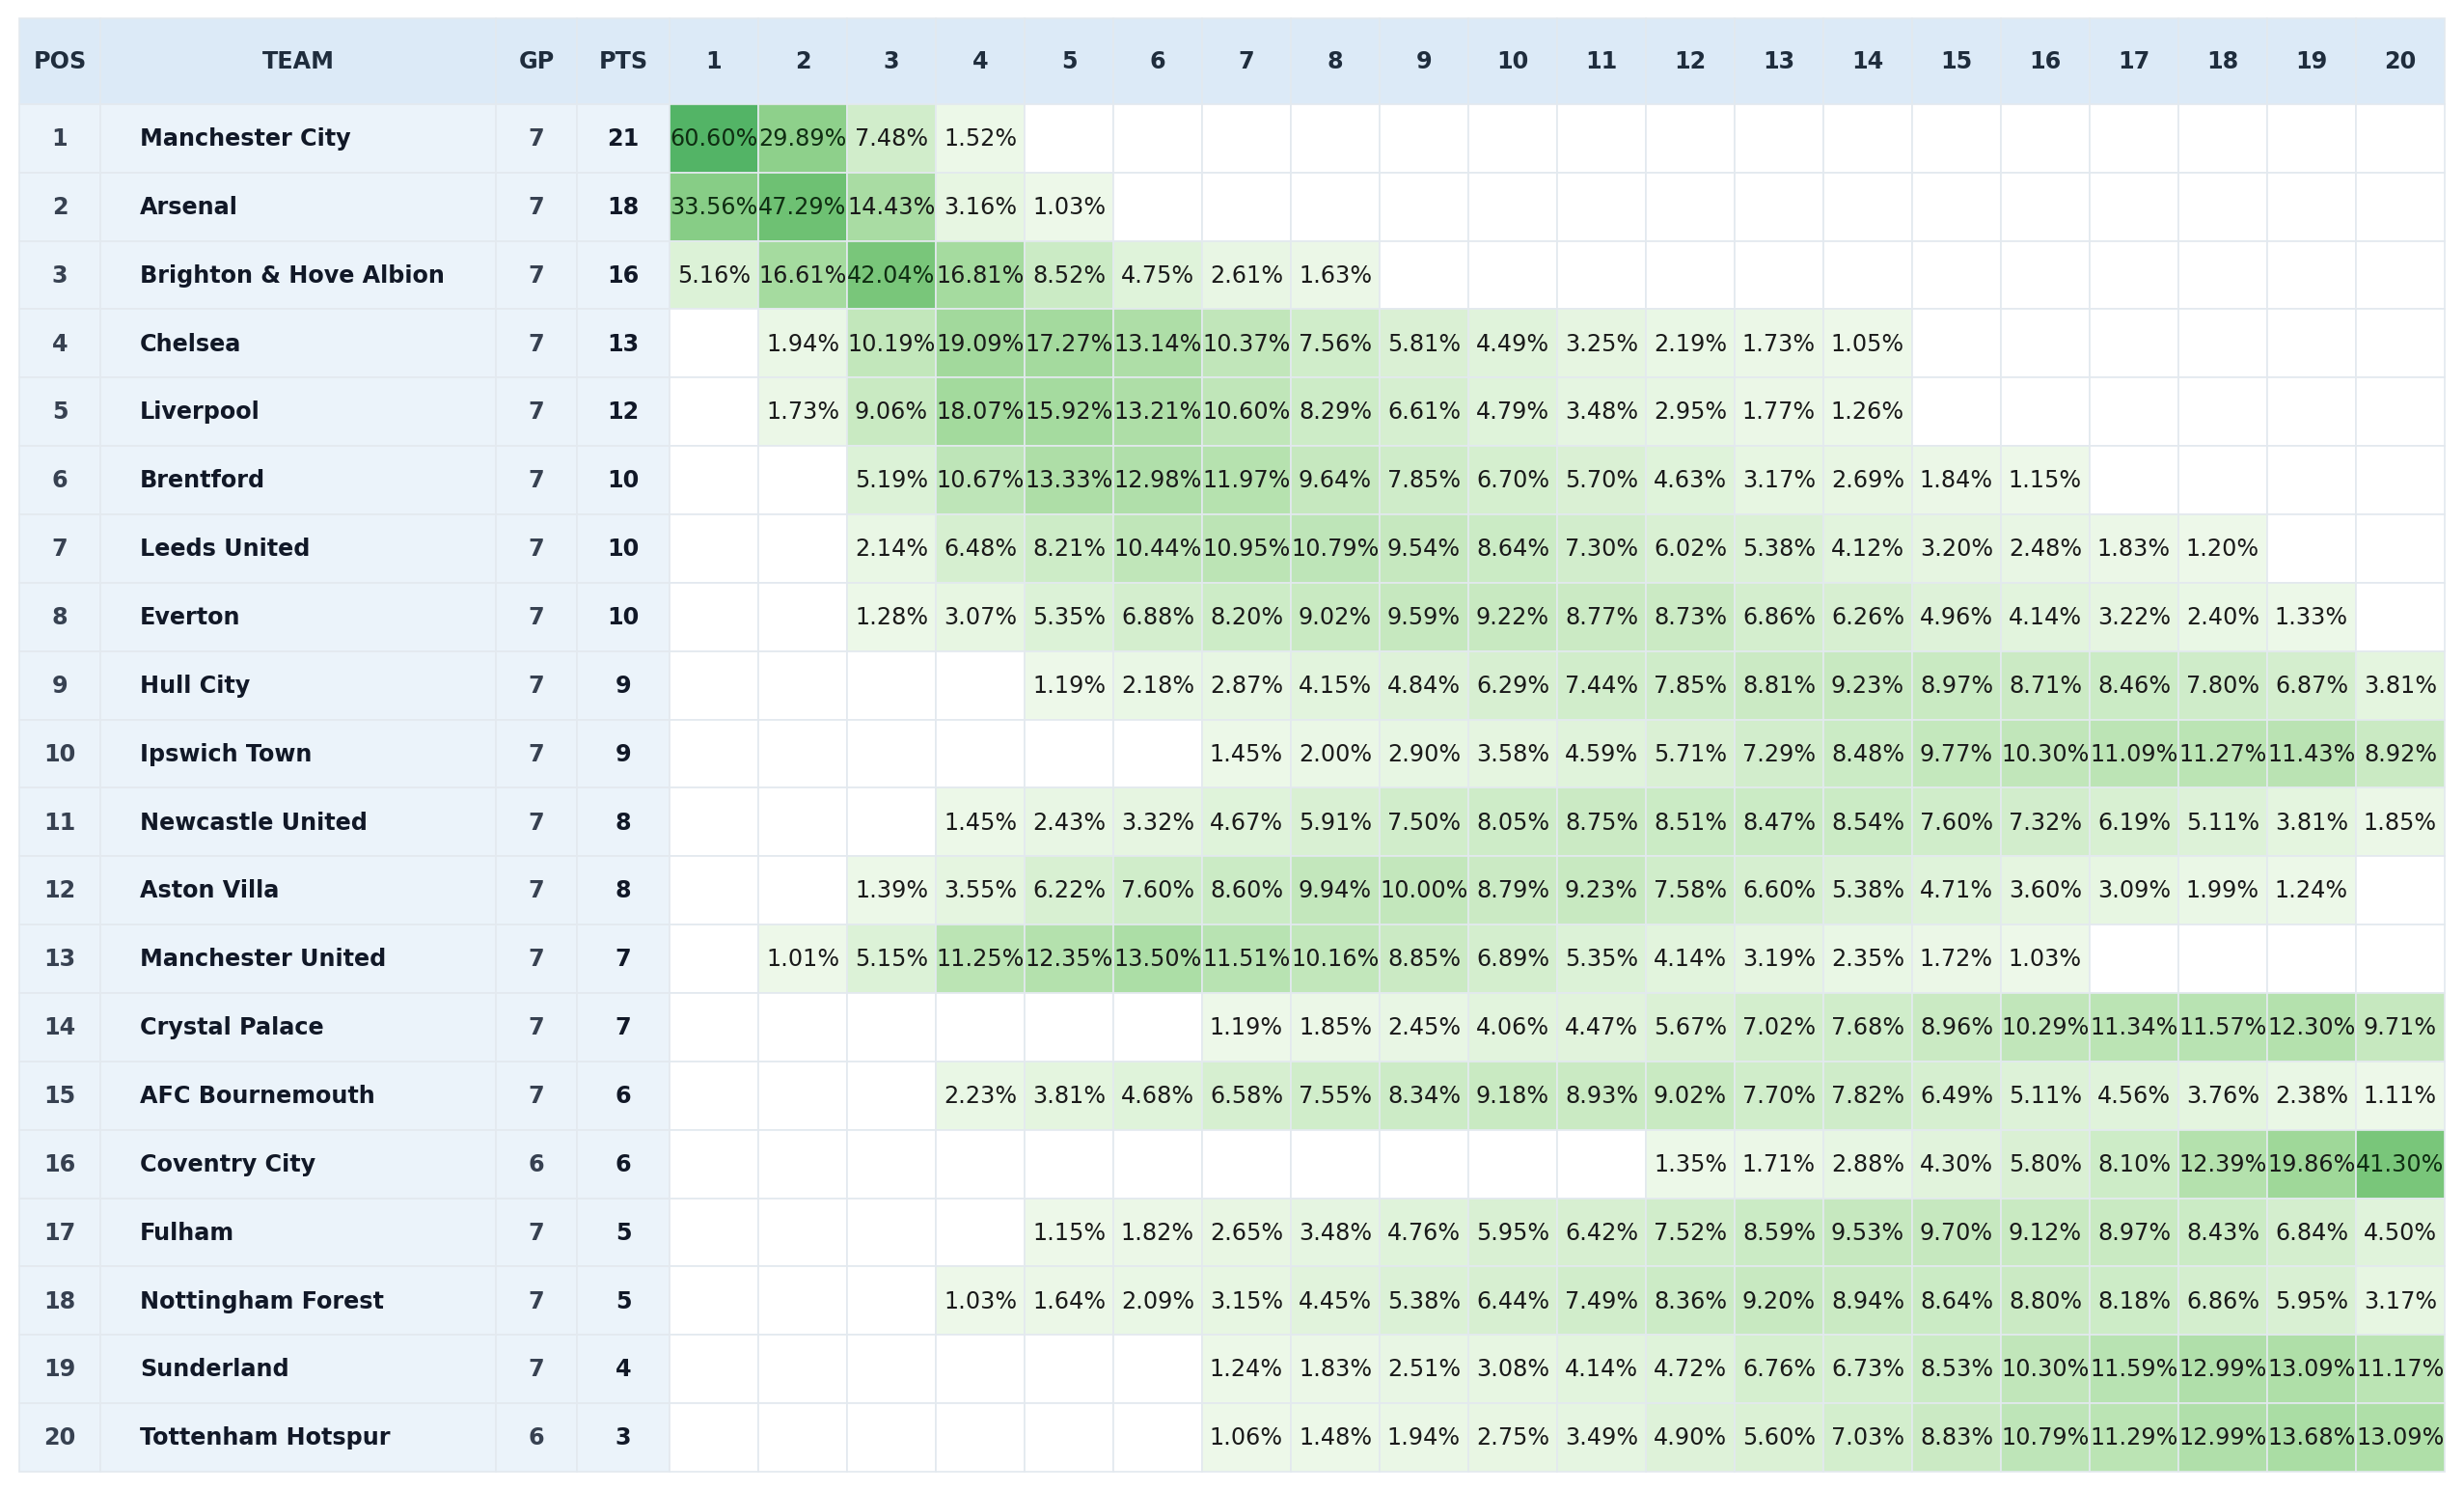

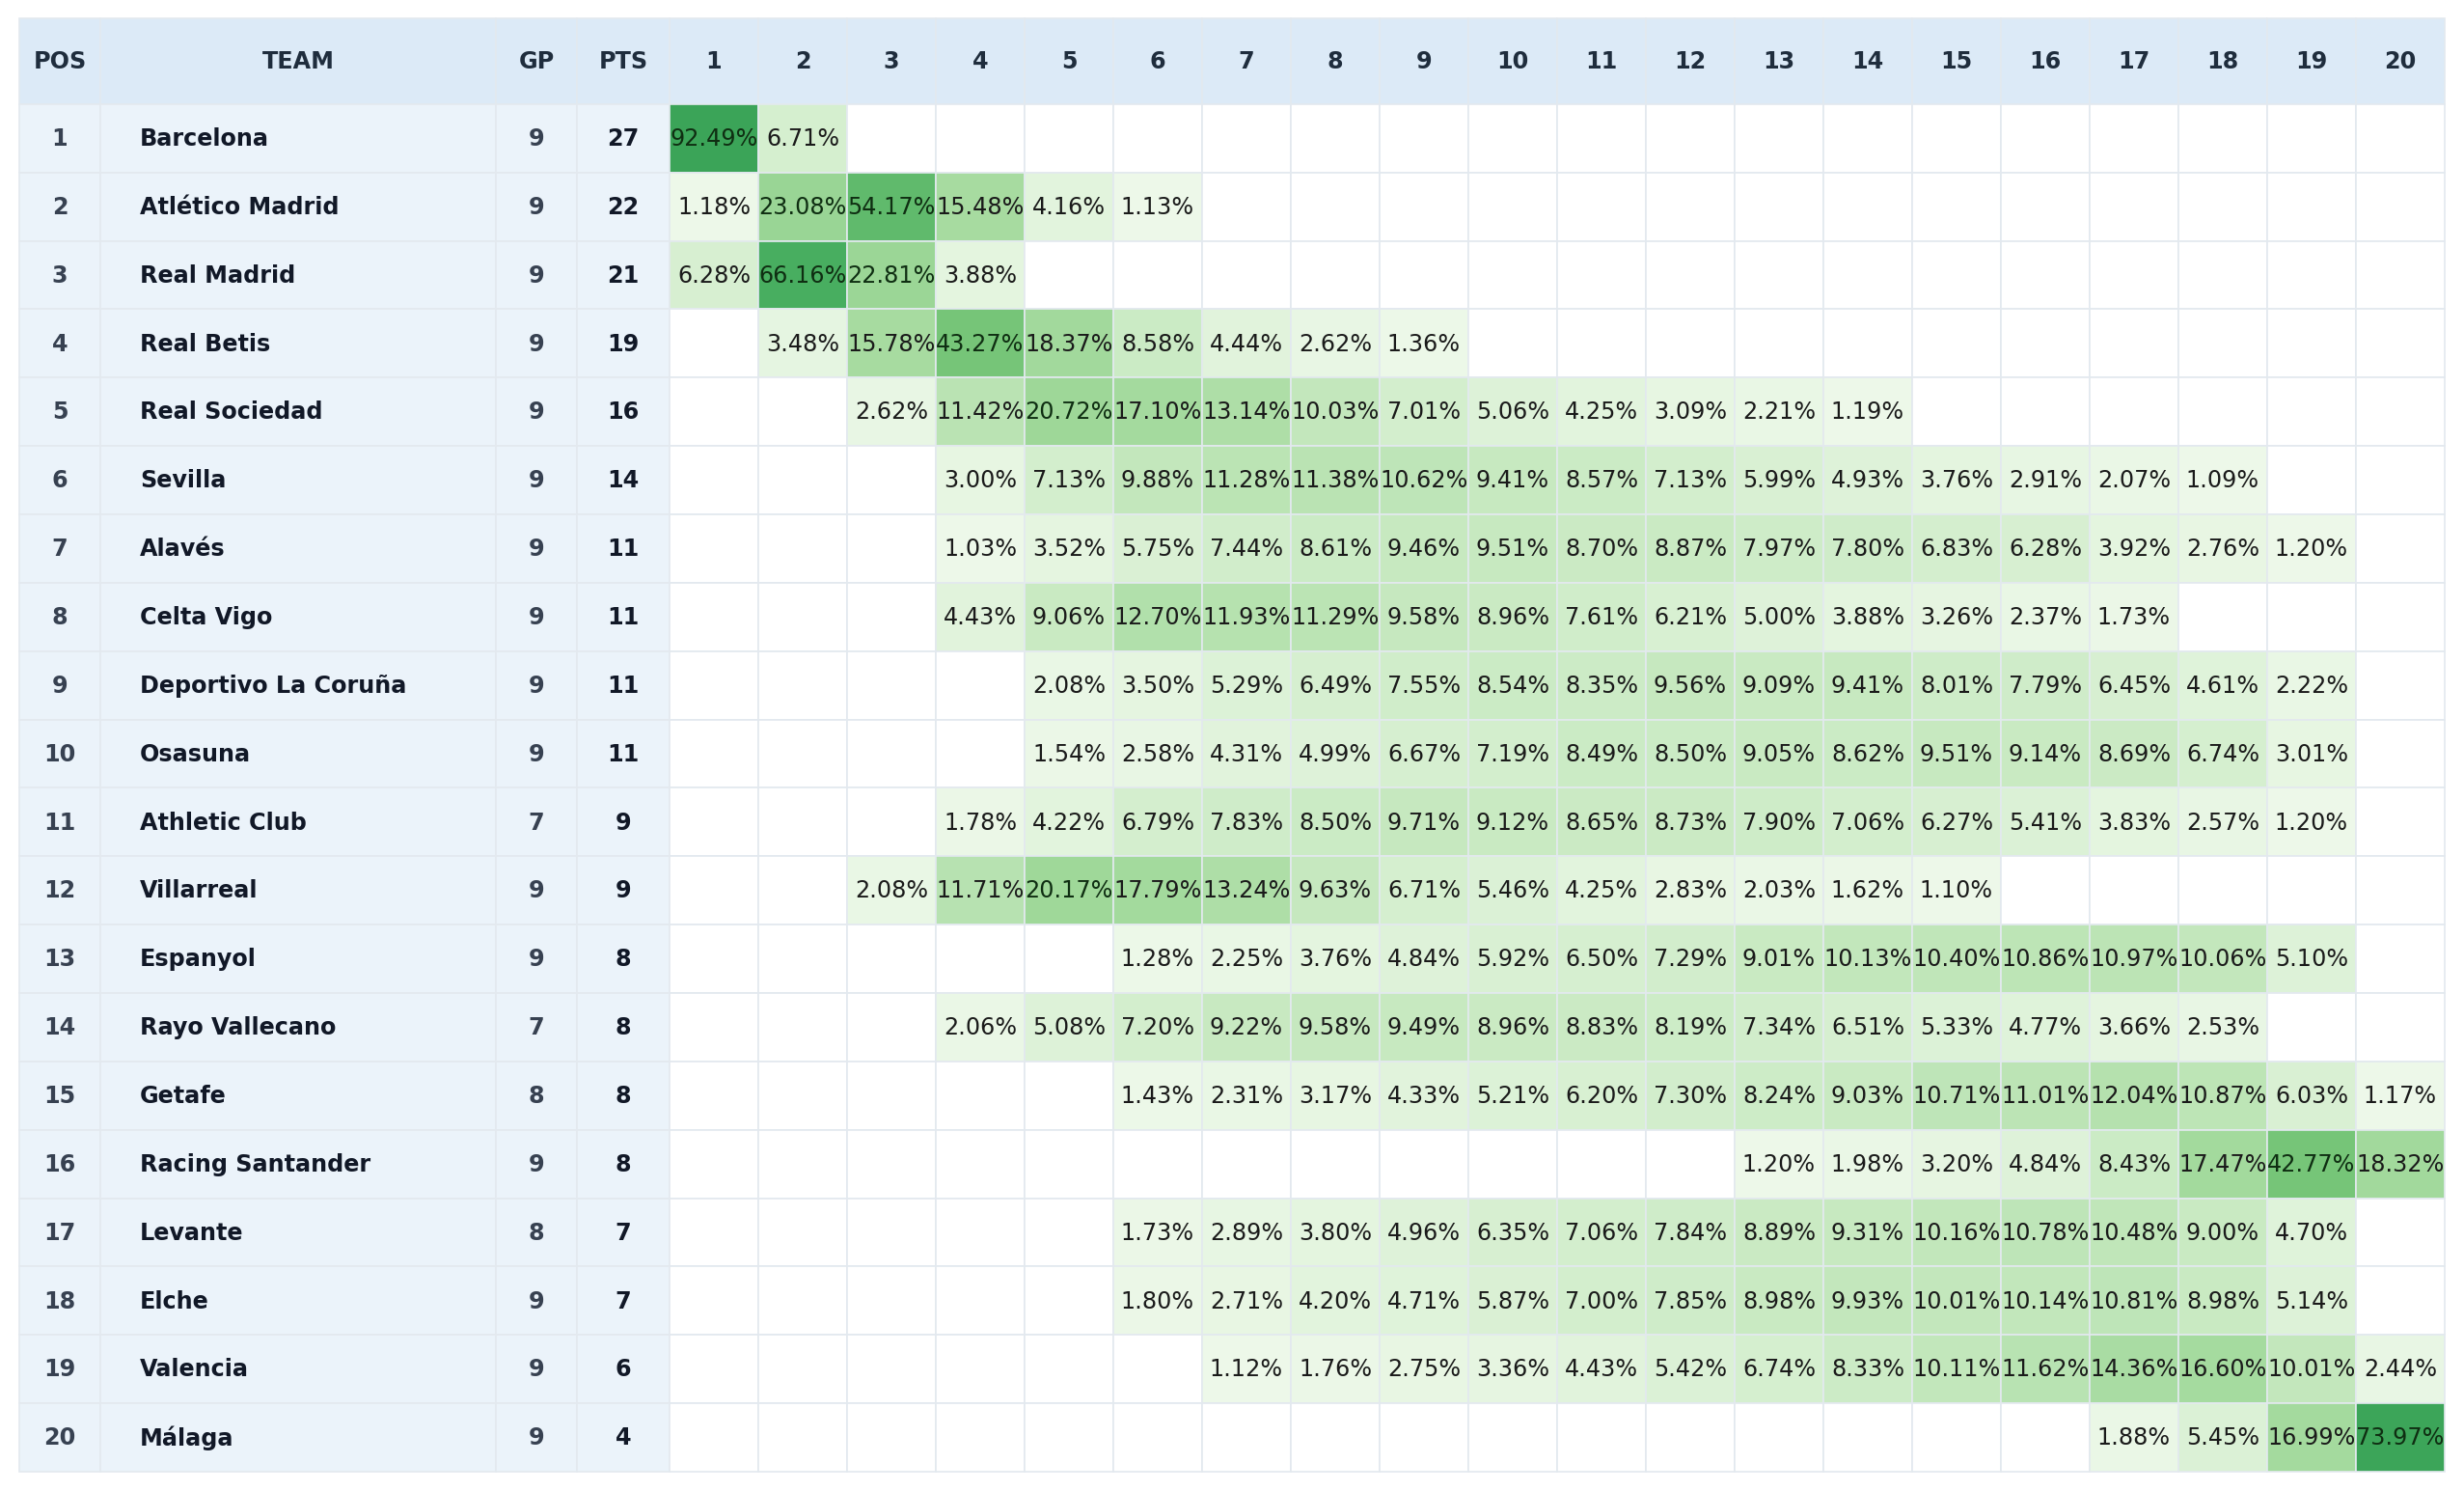

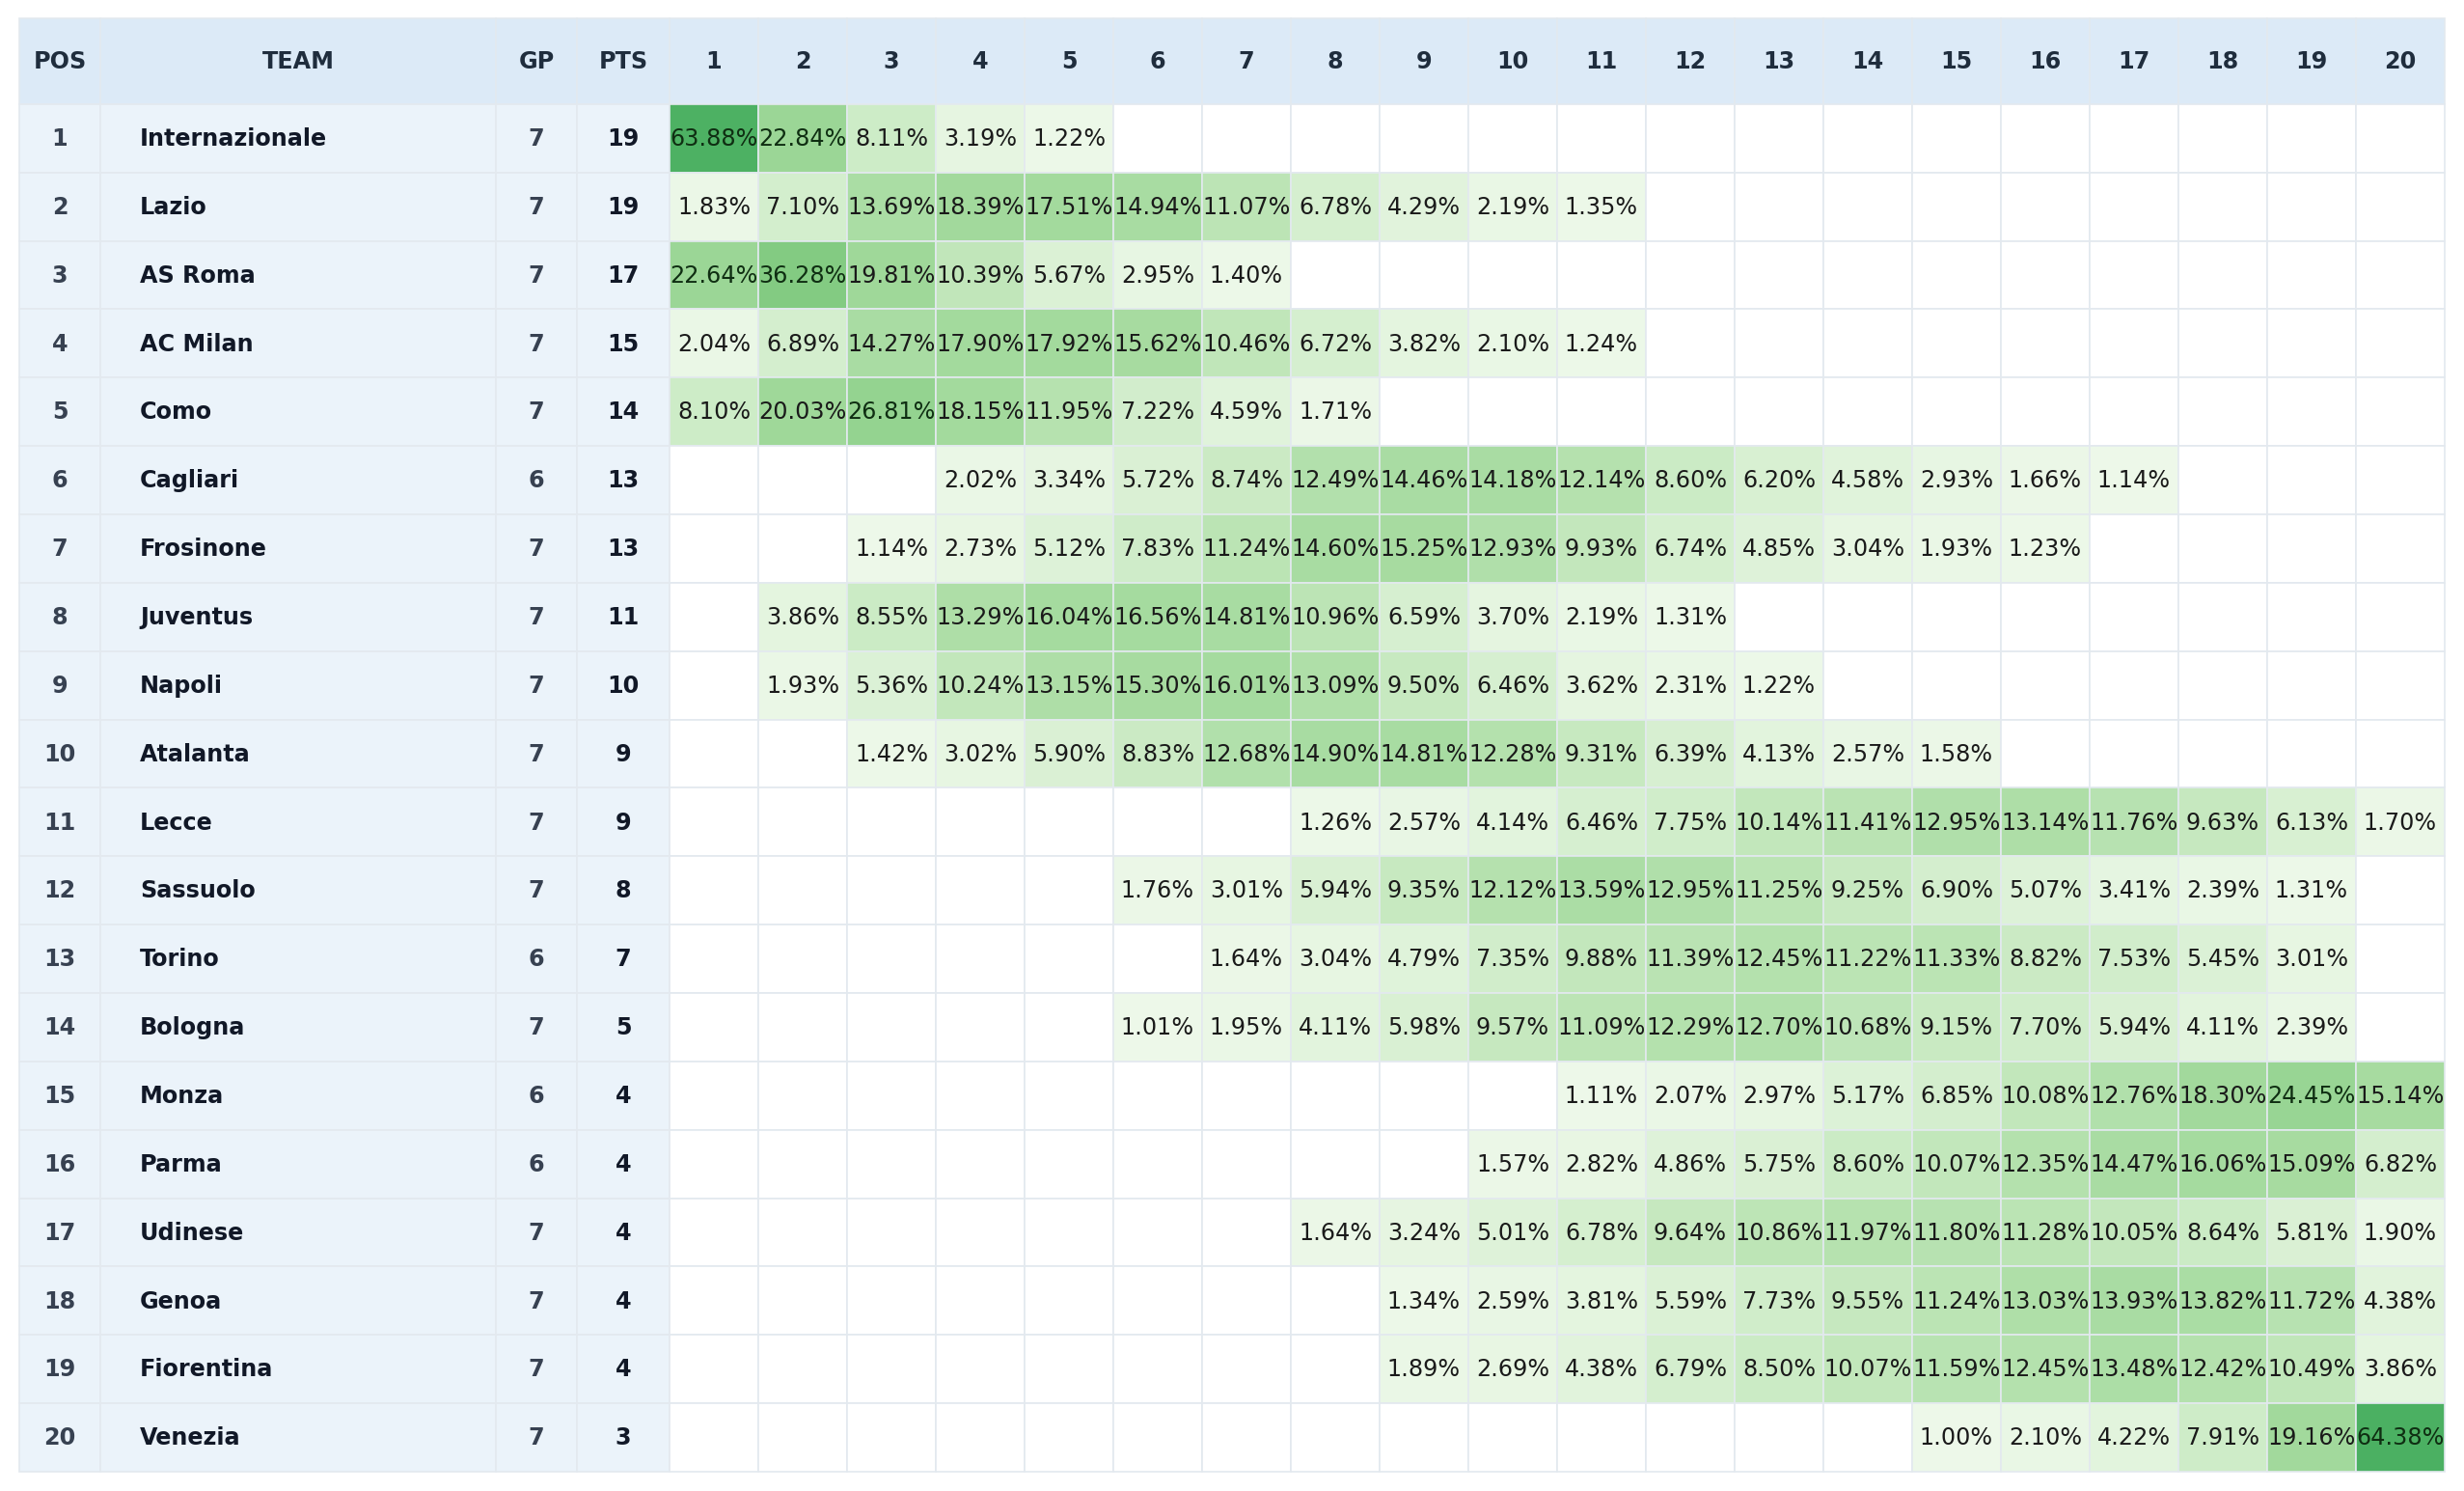

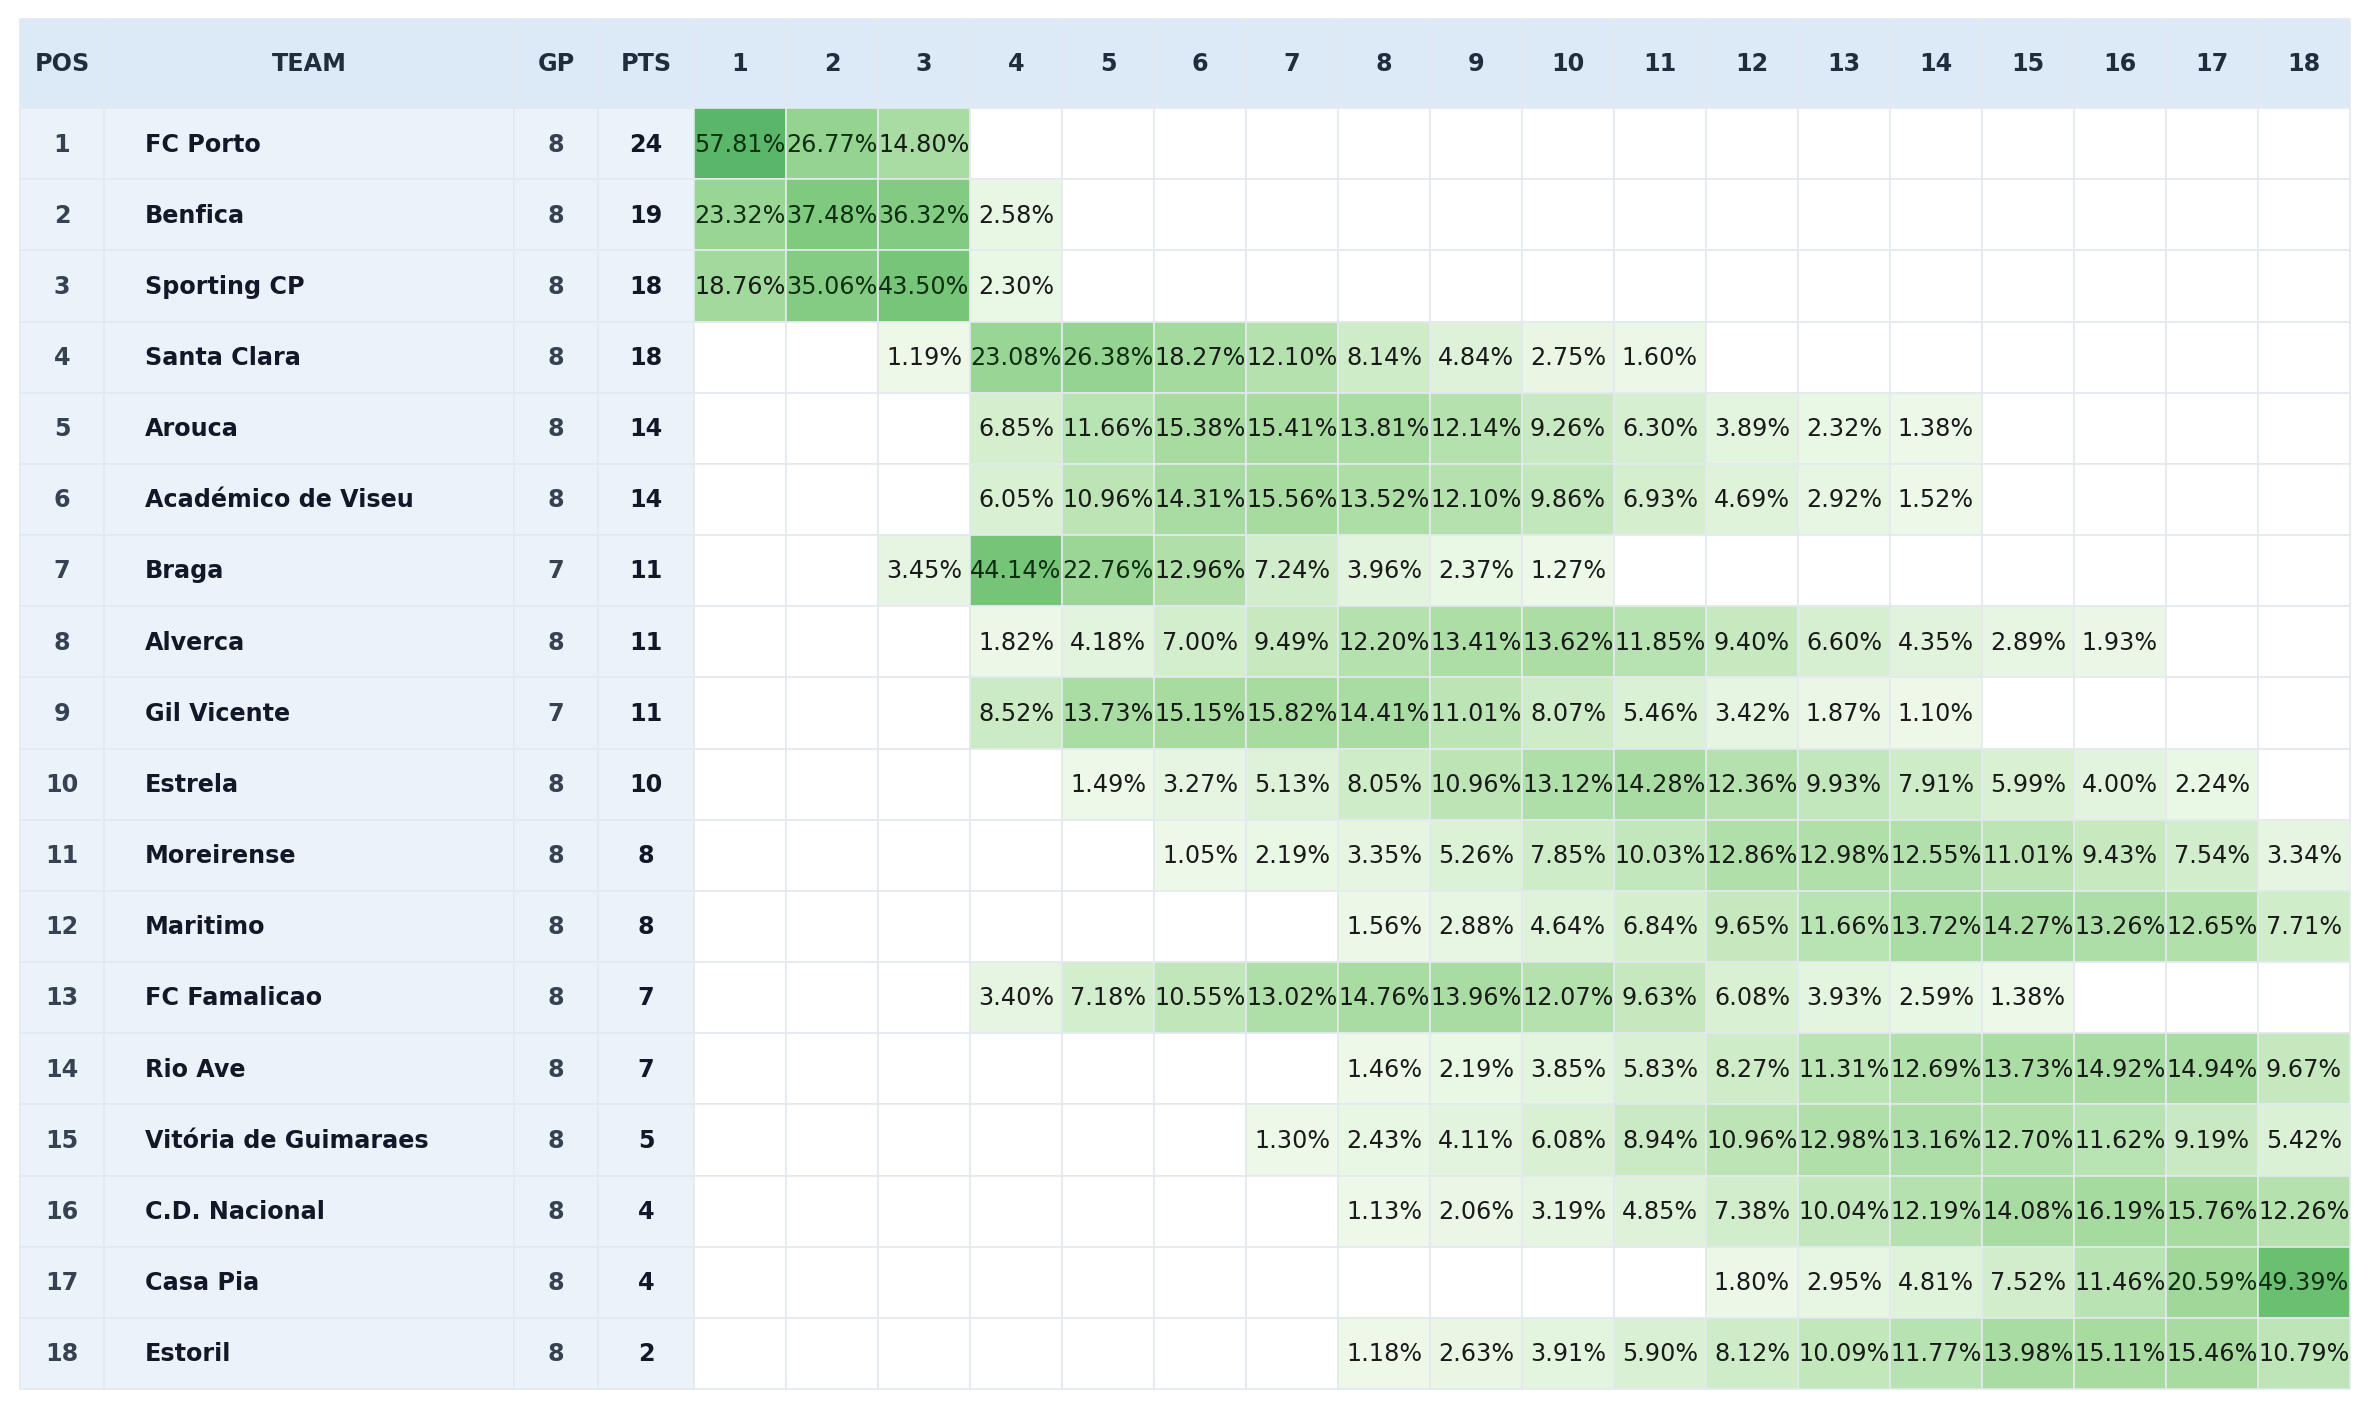

In [13]:
def create_green_cmap():
    greens = plt.cm.Greens
    return LinearSegmentedColormap.from_list("Greens_soft", greens(np.linspace(0.05, 0.65, 256)))


def zero_style(val):
    return "background-color: white !important;" if val < 1 else ""


def color_scale(val, mid=0.14, max_val=0.75):
    if val >= max_val:
        return 1.0
    elif val <= mid:
        return val / mid * 0.5
    else:
        return 0.5 + (val - mid) / (max_val - mid) * 0.5


def style_position_table(pos_pct, table):
    meta = table[["team", "position", "gp", "pts"]].set_index("team").rename(
        columns={"position": "POS", "gp": "GP", "pts": "PTS"}
    )
    meta = meta.loc[pos_pct.index]

    pos_pct = pos_pct.copy()
    pos_pct.index = pd.MultiIndex.from_arrays(
        [meta["POS"].astype(int), meta.index, meta["GP"].astype(int), meta["PTS"].astype(int)],
        names=["POS", "TEAM", "GP", "PTS"],
    )

    display_df = pos_pct.reset_index()
    text_cols = ["POS", "TEAM", "GP", "PTS"]
    num_cols = display_df.columns.difference(text_cols)
    vmax = max(display_df[num_cols].max().max(), 1)
    color_data = display_df[num_cols].divide(vmax).apply(lambda s: s.map(color_scale)) * vmax

    return (
        display_df.style
        .background_gradient(cmap=create_green_cmap(), vmin=0, vmax=vmax, gmap=color_data, axis=None)
        .map(zero_style, subset=num_cols)
        .format({col: "{:.2f}%" for col in num_cols})
        .set_properties(subset=["POS", "GP", "PTS"], **{"text-align": "center", "font-size": "12px", "font-weight": "600"})
        .set_properties(subset=["TEAM"], **{"text-align": "left", "font-size": "12px", "font-weight": "600"})
        .set_properties(subset=num_cols, **{"text-align": "center", "font-size": "12px", "font-weight": "500"})
        .hide(axis="index")
    )


styled_tables = {
    league: style_position_table(position_pct_all[league], standings[league])
    for league in position_pct_all
}

styled_tables.get("premierleague_england")


# #### A dependency-light export: the same table as a plain matplotlib figure
#
# The styled table above only renders inside a notebook or browser — pandas' `Styler` produces
# HTML, not an image. Turning it into a PNG (for a slide deck, a report, a Slack message) normally
# means reaching for a headless-browser export tool, which is a heavy dependency for what is,
# visually, just a coloured grid. A plain `matplotlib` table reproduces the exact same look — same
# POS/TEAM/GP/PTS columns, same green gradient, same rounding — as the live dashboard's own styled
# table (they share `create_green_cmap`/`color_scale`), with no extra dependency beyond what
# Section 0 already imports.

TABLE_HEADER_BG = "#DCEAF7"
TABLE_META_BG = "#EBF3FA"
TABLE_GRID = "#E3E9EF"


def plot_position_table(pos_pct, table, league_name, save_path=None):
    meta = table[["team", "position", "gp", "pts"]].set_index("team")
    meta = meta.loc[pos_pct.index]
    order = meta.sort_values("position").index
    pos_pct = pos_pct.loc[order]
    meta = meta.loc[order]

    n_teams, n_pos = pos_pct.shape
    cmap = create_green_cmap()

    col_labels = ["POS", "TEAM", "GP", "PTS"] + [str(c) for c in pos_pct.columns]
    meta_inches = [0.42, 2.05, 0.42, 0.48]
    data_col_in = 0.46
    fig_w = sum(meta_inches) + data_col_in * n_pos
    fig_h = 0.34 * (n_teams + 1) + 0.3

    fig = plt.figure(figsize=(fig_w, fig_h), dpi=200)
    fig.patch.set_facecolor("white")
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_facecolor("white")
    ax.axis("off")

    cell_text, cell_colors, cell_text_colors = [], [], []
    for team in order:
        row_text = [str(int(meta.loc[team, "position"])), team, str(int(meta.loc[team, "gp"])), str(int(meta.loc[team, "pts"]))]
        row_colors = [TABLE_META_BG] * 4
        row_text_colors = ["#374151", "#111827", "#374151", "#111827"]
        for c in pos_pct.columns:
            val = pos_pct.loc[team, c]
            if val < 1:
                row_text.append("")
                row_colors.append("#FFFFFF")
                row_text_colors.append("#374151")
            else:
                row_text.append(f"{val:.2f}%")
                scaled = color_scale(val / 100, mid=0.14, max_val=0.75)
                row_colors.append(cmap(scaled))
                row_text_colors.append("#0f2e12" if scaled > 0.55 else "#1a1a1a")
        cell_text.append(row_text)
        cell_colors.append(row_colors)
        cell_text_colors.append(row_text_colors)

    tbl = ax.table(cellText=cell_text, cellColours=cell_colors, colLabels=col_labels, cellLoc="center", loc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(8.6)

    col_widths = [w / fig_w for w in meta_inches + [data_col_in] * n_pos]
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor(TABLE_GRID)
        cell.set_linewidth(0.6)
        cell.set_width(col_widths[c])
        cell.set_height(1.0 / (n_teams + 1))
        if r == 0:
            cell.set_facecolor(TABLE_HEADER_BG)
            cell.get_text().set_fontweight("bold")
            cell.get_text().set_color("#1f2d3d")
            cell.set_height(1.25 / (n_teams + 1))
        else:
            cell.get_text().set_color(cell_text_colors[r - 1][c])
            if c == 1:
                cell.get_text().set_ha("left")
                cell.get_text().set_fontweight("bold")
            if c in (0, 2, 3):
                cell.get_text().set_fontweight("bold")

    if save_path:
        fig.savefig(save_path, dpi=220, facecolor="white")
        print(f"Saved: {save_path}")
    return fig


# Not saved to disk here -- the tables actually used in the deck/masterclass are real
# screenshots taken from the live dashboard, not exported from this notebook. This just
# reproduces the same rendering inline so the notebook still shows what the simulator does.
for lg in ["premierleague_england", "laliga_spain", "seriea_italy", "primeiraliga_portugal"]:
    if lg in position_pct_all:
        plot_position_table(position_pct_all[lg], standings[lg], lg)
        plt.show()

## 10. Validating the model against the market

There's no ground truth to validate a *probability* against — a season only plays out once, so you never learn "the true probability Arsenal finish 3rd was 22%." What you *can* check is whether the model's match-level probabilities are close to the market's, since the market is the best available proxy for well-calibrated odds (millions of pounds of informed betting pressure make it self-correcting in ways a single historical-goals model isn't).

Comparing the Poisson model's probabilities to the de-vigged bookmaker probabilities, match by match, and computing RMSE across the three outcomes gives a single number to track over time. In the original single-league notebook this hovered between 0.075 and 0.090 across many re-runs — stable enough to trust the model isn't systematically miscalibrated, while varying enough (bookmaker odds move) that a single reading shouldn't be over-interpreted. A more complete version of this section would report a proper scoring rule (Brier score or log loss) rather than RMSE, since those are the metrics actually optimised by well-calibrated probabilistic forecasts — left as a clearly-labelled extension.

On the 19/10/2026 run, six to eleven games into most seasons, the nine leagues range from 0.077 (Championship) and 0.093 (Eredivisie) to 0.160 (La Liga), with the Premier League at 0.099. Most are still wider than the 0.075–0.090 mid-season band, which is what you'd expect this early: ratings are still heavily shrunk towards average, and only the next round or two of fixtures has odds to compare against. (`RMSE_total` sums the squared errors of home, draw, and away before averaging over matches, so it's about √3 times the per-outcome RMSE.)

Worth naming explicitly: this comparison only means something if it's diffing the model's *own* estimate against the market, not the already-blended output against itself. The first version of this section did exactly that by accident — comparing `p_home_final` (which literally **is** the market's number wherever the market exists, by construction of Section 7's blend) against the market reported a perfect RMSE of 0.0000 for every league, which looks like a triumphant result and is actually a tautology. The fix was re-exposing the pure, pre-blend model columns from Section 7 so there's something genuinely independent to check the market against.


In [14]:
def validate_against_market(df_final, df_book):
    """Comparing the BLENDED p_*_final probabilities to the market is circular: wherever market
    odds exist, p_*_final simply *is* the market probability by construction (Section 7's
    np.where falls back to the model only when the market is missing) -- diffing it against the
    market there measures nothing but floating-point equality. This compares the PURE, pre-blend
    model columns (p_home_win/p_draw/p_away_win) against the market instead, on the subset of
    matches where both exist -- an actual test of whether the Poisson model agrees with the
    market, not a tautology. The first version of this notebook's Section 10 had this exact bug:
    it read as a real validation step and silently reported RMSE = 0.0000 for every league."""
    compare = df_final.merge(
        df_book.rename(columns={"home_team": "homeTeam", "away_team": "awayTeam"}),
        on=["homeTeam", "awayTeam"], how="inner", suffixes=("", "_book")
    )
    if compare.empty:
        return None

    rmse_home = np.sqrt(np.mean((compare["p_home_win"] - compare["p_home_book"]) ** 2))
    rmse_draw = np.sqrt(np.mean((compare["p_draw"] - compare["p_draw_book"]) ** 2))
    rmse_away = np.sqrt(np.mean((compare["p_away_win"] - compare["p_away_book"]) ** 2))
    rmse_total = np.sqrt(np.mean(
        (compare["p_home_win"] - compare["p_home_book"]) ** 2 +
        (compare["p_draw"] - compare["p_draw_book"]) ** 2 +
        (compare["p_away_win"] - compare["p_away_book"]) ** 2
    ))
    return {"n_matches": len(compare), "rmse_home": rmse_home, "rmse_draw": rmse_draw,
            "rmse_away": rmse_away, "rmse_total": rmse_total}


for league in active_leagues:
    if league not in df_simulation_all:
        continue
    result = validate_against_market(df_simulation_all[league], odds_book.get(f"odds_{league}", pd.DataFrame()))
    if result:
        print(f"{league}: n={result['n_matches']}, RMSE_total={result['rmse_total']:.4f}")


premierleague_england: n=21, RMSE_total=0.0994
championship_england: n=13, RMSE_total=0.0770
seriea_italy: n=22, RMSE_total=0.1018
laliga_spain: n=21, RMSE_total=0.1601
bundesliga_germany: n=18, RMSE_total=0.1409
ligue1_france: n=18, RMSE_total=0.1352
eredivisie_netherlands: n=9, RMSE_total=0.0928
seriea_brazil: n=16, RMSE_total=0.1264
primeiraliga_portugal: n=10, RMSE_total=0.1169


## 11. From notebook to production: the daily-refresh pipeline

Everything above is the *narrative* version, meant to be read top to bottom. `precompute_simulations.py` in the repo is the same logic re-organised for unattended daily execution: it imports the four pipeline modules (`1_dataset_creation.py` → `4_simulations.py`), runs the standings-changed check from Section 1 to skip work when nothing has moved, classifies leagues as active/finished exactly as in Section 5, blends current + previous season for ratings exactly as in Section 6, and pickles the position-count and position-percentage tables to disk. A GitHub Actions workflow runs it daily; a Streamlit app (`app.py`) reads the pickled results straight off disk to serve the interactive dashboard at [football-league-simulator.streamlit.app](https://football-league-simulator.streamlit.app/) without ever re-running a simulation on page load.

Two differences from this notebook, both covered above as they came up: the standings scraper runs Playwright's headless Chromium *unconditionally* rather than as a fallback (Section 1), since every request on a GitHub Actions runner would otherwise hit ESPN's WAF challenge; and the missing-fixture-leg backfill (Section 5) disambiguates "missing from the past" vs "missing from the future" properly using games-played counts, instead of this notebook's simplified always-goes-to-future-fixtures version.

The engineering lesson worth pulling out for the masterclass: the *model* (Sections 6–8) barely changed at all going from prototype to production. What changed was everything **around** it: retries, caching, idempotency checks, graceful degradation when one league's data is temporarily missing, and three genuine data bugs (the ESPN code regex, the blended-shrinkage trust signal, the both-legs-missing case) that only surfaced after running unattended for a few weeks. That's usually where the real effort in "shipping a model" goes.


One more production-only concern surfaced once a ninth league (Primeira Liga) pushed the daily GitHub Actions run past half an hour: **unattended scheduled jobs have a runtime budget too, and it degrades quietly.** Three sequential phases were each individually fine but summed to over 30 minutes: ESPN scraping (9 sequential Playwright page loads), football-data.org calls (roughly 19 to 20 requests for fixtures plus two seasons of history across all 9 leagues, hitting the free tier's ~10-requests-per-minute cap and eating a wasted request plus a blind 60-second sleep almost every run), and the Monte Carlo step itself (10,000 simulations per active league, looped one match at a time in pure Python, run one league after another). None of these are model problems. They belong in the same "everything around the model" category as Section 5's data bugs, just showing up as *time* instead of *wrong numbers*.

None of the three needed the same fix, and two of them needed close to opposite ones. ESPN's 9 leagues now scrape concurrently, capped at 3 at once on purpose (a burst of 9 simultaneous requests from one IP looks more bot-like, not less). football-data.org's calls go the other way: they're proactively paced to stay just under its limit, instead of firing as fast as possible and reactively backing off after getting rejected. Each active league's Monte Carlo run now goes to its own CPU core via `multiprocessing`, instead of one core working through them one at a time. Those three fixes alone took the job from over 30 minutes to under 3.

A fourth fix went further, for a different reason than the daily schedule. Splitting the simulation across cores let every league run at the same time, but it never made any single league's simulation itself any faster: the underlying loop was still stepping through matches one at a time in pure Python. Rewriting that loop as a single batch of numpy operations (see the vectorised version in `4_simulations.py`) dropped one league's simulation from a couple of minutes to about two seconds. The total daily job barely moved as a result, since checkout, dependency install and the browser install already cost close to a minute on their own with little left to save. The value of that fourth fix was making the simulation step fast in absolute terms, not shaving more off an already-small scheduled total.

## 12. Discussion — talking in probabilities, and where tracking data could take this further

### The one idea to leave with
Every output in this notebook is a distribution, never a point estimate. Section 9's table doesn't say "Arsenal will finish 1st" — it says something closer to *"Arsenal: 34% 1st, 27% 2nd, 19% 3rd, …"*. That's not a stylistic choice, it's the correct way to communicate the output of a stochastic simulation: a single Monte Carlo run is one sample from an underlying distribution, and reporting only the most likely sample throws away almost all of the useful information (how close is 2nd? how real is the relegation risk?). If a masterclass audience takes away one habit, it should be this one.

### Where this model is weakest
The attack/defence ratings in Section 6 are built entirely from **goals** — a very sparse, very noisy, backward-looking signal. A typical match produces 0–5 goals total; that's an extremely small number of observations from which to infer a team's underlying quality, which is precisely *why* Section 6 needs a shrinkage step and Section 4 needs to blend in a prior season at all. Goals are also slow: a team can be playing much better (or worse) football for weeks before that shows up as a statistically detectable shift in goals scored/conceded.

### Where tracking data changes the picture
This is exactly the gap that player- and ball-tracking data (of the kind SkillCorner provides) is built to close. Instead of inferring "attacking strength" only from the rare, high-variance event of a goal, tracking data exposes the much higher-frequency processes that *produce* goals:

- **Pressing intensity & PPDA-style pressure metrics** — dozens of pressing events per match rather than 0–5 goals; a far larger sample per game to estimate a defensive-strength parameter from.
- **Space creation & dangerous off-ball runs** — chance quality that precedes a shot, let alone a goal, catching a team's attacking improvement before it shows up on the scoreboard.
- **Physical output (high-speed running, sprint counts, distance covered)** — a leading indicator of fatigue and fixture-congestion risk, relevant to how confidently a rating should be projected forward into a busy run of fixtures.
- **Line-breaking passes / possession value models built on full spatial data** — a continuous-valued signal for attacking quality, rather than the binary "did this shot go in".

Concretely, this wouldn't replace the architecture built in this notebook — it would **upgrade what feeds Section 6 and 7**. The pipeline stays: *estimate a rate parameter per team → Poisson (or richer) model → Monte Carlo simulate the season → report a full distribution*. What improves is the quality and speed of the rate estimate itself: richer, higher-frequency inputs mean ratings converge from fewer matches, need less aggressive early-season shrinkage, and react faster to genuine changes in team strength (a new manager, a key injury) instead of waiting for enough goals to accumulate as evidence.

The deliverable, though, doesn't change. Better inputs produce a sharper distribution — not a point prediction. "Arsenal has a 41% chance of finishing 1st" said with tracking-informed ratings is still a probability statement; it's just a more confident, better-calibrated one than the goals-only version in Section 6. That's the upgrade path worth pursuing next, and it's exactly why the annex below (rugby) is included: it's a worked example of what happens when the *simple* version of this reasoning (one Poisson count, one home-advantage term, a deep market to lean on) genuinely isn't enough, and something richer is required from the start.


---

## 13. Annex — Predicting rugby: why football's simplicity doesn't transfer

Everything above generalises across nine football leagues with almost no per-league special-casing, which might suggest the same recipe — one Poisson count per team, three outcomes, one home-advantage term, blend with a betting market — would port cleanly to any other league-format sport. It doesn't. This annex is drawn directly from my English Rugby Premiership prediction work (same goal: full position-probability tables via Monte Carlo simulation), and walks through exactly where and why the football approach breaks down, and what had to change instead.

The short version: football is a *special case* — two goal counts, three outcomes, uniform home advantage, a deep liquid market — not the general template for "predict a league." Rugby breaks every one of those simplifying assumptions at once.


### A. One scoring event vs. four correlated ones

Football has one thing to model per team per match: goals. Rugby points come from four *different* scoring actions, each with its own rate and its own home-advantage behaviour — tries (5pts), conversions (2pts, conditional on a try), penalties (3pts), and drop goals (3pts). The final score is not one Poisson draw; it's a **derived combination** of (at least) four separate underlying processes. Modelling rugby "the football way" — one Poisson count for points — throws away exactly the structure (tries vs. penalties behave completely differently, see below) that actually matters for the bonus-point system.

### B. Home advantage isn't uniform across those components

In football, a single home-advantage scalar applied to the one goals process is a reasonable simplification. In rugby, checking it directly reveals it isn't transferable *within* the sport, let alone across sports:

> **Note:** the two code snippets below are excerpted from my actual rugby notebook to show the real logic, not re-run here — `past_premierships` and the rugby `team_strengths` table depend on the Sky Sports / TNT Sports scraping pipeline from that notebook, which this football notebook doesn't load. They're `raw` cells for exactly that reason: read them, don't run them.


# From the rugby notebook — checking whether a single home-advantage term is even valid within rugby itself
home_advantage_tries = past_premierships['Tries_home'].mean() - past_premierships['Tries_away'].mean()
print("Home advantage (average tries):", home_advantage_tries)

home_advantage_penalties = past_premierships['Penalties_home'].mean() - past_premierships['Penalties_away'].mean()
print("Home advantage (average penalties):", home_advantage_penalties)
# Result: small, and even negative in some seasons — no real home advantage on penalties, so it's
# left out entirely for that component rather than forcing the same global term onto every scoring type.


A single `home_adv` constant (fine for one goals process) would silently misapply a real, sizeable effect (tries) onto a component that shows no such effect (penalties) if it weren't checked and separated out per component. This is a direct instance of a general rule: **an assumption that's harmless for one signal (uniform home advantage across all of "goals") can be actively wrong once you disaggregate into multiple signals.** Always check whether a simplifying assumption still holds at the level of granularity you're actually modelling.

### C. Bonus points turn 3 outcomes into 20 — and remove the closed-form shortcut

Football's Poisson model works because the final step — turning two goal counts into home win / draw / away win — is a simple comparison (`i > j`, `i == j`, `i < j`) over a *manageable* scoreline grid (7×7 at `max_goals=6`). League points then follow directly and deterministically from that one comparison (win = 3, draw = 1, loss = 0).

Rugby's win/draw/loss result is necessary but not sufficient to know the league points awarded, because of bonus points: any team scoring 4+ tries gets a try bonus point, win or lose, and a losing team also gets a bonus point for losing by 7 points or fewer. That means league points depend jointly on **four correlated counts** (tries, conversions, penalties, drops) **and** a margin condition, which multiplies out to 20 mutually exclusive result+bonus combinations per match rather than football's 3. There's no equivalent 7×7 scoreline-grid shortcut for a 20-way joint outcome built from four dependent Poisson-like counts and a derived margin condition — so instead of computing probabilities analytically, each match itself has to be **simulated** (thousands of times) just to get its 20-way outcome distribution, *before* that distribution is used as the input to simulating the season. Football needs one layer of Monte Carlo (the season). Rugby needs two: one to resolve each match's bonus-point outcome distribution, nested inside the one that simulates the season.


# Adapted from the rugby notebook: resolving one match's bonus-point outcome distribution by
# simulation, because no closed-form shortcut exists for the joint distribution of tries,
# conversions, penalties, drops AND the bonus-point margin condition.

def simulate_match_joint(home_team, away_team, team_strengths, sims=10000):
    """Simulate a match `sims` times and return probabilities for all 20 mutually exclusive
    result + bonus-point outcomes (16 win/loss combinations x bonus type, plus 4 draw combinations)."""
    home = team_strengths.loc[home_team]
    away = team_strengths.loc[away_team]

    home_tries_exp = home['attack_tries'] * away['defense_tries'] * home_advantage_tries * league_avg_tries
    away_tries_exp = away['attack_tries'] * home['defense_tries'] * league_avg_tries
    home_pen_exp = home['attack_penalties'] * away['defense_penalties'] * league_avg_penalties
    away_pen_exp = away['attack_penalties'] * home['defense_penalties'] * league_avg_penalties
    home_drop_exp = home['attack_drops'] * away['defense_drops'] * league_avg_drops
    away_drop_exp = away['attack_drops'] * home['defense_drops'] * league_avg_drops

    valid_keys = [
        'win_no_bonus_lose_no_bonus', 'win_no_bonus_lose_try_bonus', 'win_no_bonus_lose_close_bonus', 'win_no_bonus_lose_bonus2',
        'win_bonus_lose_no_bonus', 'win_bonus_lose_try_bonus', 'win_bonus_lose_close_bonus', 'win_bonus_lose_bonus2',
        'lose_no_bonus_win_no_bonus', 'lose_no_bonus_win_bonus', 'lose_try_bonus_win_no_bonus', 'lose_try_bonus_win_bonus',
        'lose_close_bonus_win_no_bonus', 'lose_close_bonus_win_bonus', 'lose_bonus2_win_no_bonus', 'lose_bonus2_win_bonus',
        'draw_no_bonus_draw_no_bonus', 'draw_no_bonus_draw_bonus', 'draw_bonus_draw_no_bonus', 'draw_bonus_draw_bonus',
    ]
    outcome_counts = {k: 0 for k in valid_keys}

    for _ in range(sims):
        home_tries = poisson.rvs(home_tries_exp)
        away_tries = poisson.rvs(away_tries_exp)
        home_converted = min(home_tries, poisson.rvs(home_tries_exp * home['conversion_rate']))
        away_converted = min(away_tries, poisson.rvs(away_tries_exp * away['conversion_rate']))
        home_pen, away_pen = poisson.rvs(home_pen_exp), poisson.rvs(away_pen_exp)
        home_drop, away_drop = poisson.rvs(home_drop_exp), poisson.rvs(away_drop_exp)

        home_points = home_tries * 5 + home_converted * 2 + home_pen * 3 + home_drop * 3
        away_points = away_tries * 5 + away_converted * 2 + away_pen * 3 + away_drop * 3

        home_bonus_try, away_bonus_try = home_tries >= 4, away_tries >= 4
        home_bonus_close = (away_points - home_points) <= 7 and home_points < away_points
        away_bonus_close = (home_points - away_points) <= 7 and away_points < home_points

        if home_points > away_points:
            home_outcome = 'win_bonus' if home_bonus_try else 'win_no_bonus'
            away_outcome = ('lose_bonus2' if away_bonus_try and away_bonus_close else
                            'lose_try_bonus' if away_bonus_try else
                            'lose_close_bonus' if away_bonus_close else 'lose_no_bonus')
        elif home_points < away_points:
            away_outcome = 'win_bonus' if away_bonus_try else 'win_no_bonus'
            home_outcome = ('lose_bonus2' if home_bonus_try and home_bonus_close else
                            'lose_try_bonus' if home_bonus_try else
                            'lose_close_bonus' if home_bonus_close else 'lose_no_bonus')
        else:
            home_outcome = 'draw_bonus' if home_bonus_try else 'draw_no_bonus'
            away_outcome = 'draw_bonus' if away_bonus_try else 'draw_no_bonus'

        outcome_counts[f'{home_outcome}_{away_outcome}'] += 1

    return {k: v / sims for k, v in outcome_counts.items()}


# League points awarded for each of the 20 outcomes (win=4, try-scoring bonus=+1, losing bonus=+1)
points_map = {
    'win_no_bonus_lose_no_bonus': (4, 0), 'win_no_bonus_lose_try_bonus': (4, 1),
    'win_no_bonus_lose_close_bonus': (4, 1), 'win_no_bonus_lose_bonus2': (4, 2),
    'win_bonus_lose_no_bonus': (5, 0), 'win_bonus_lose_try_bonus': (5, 1),
    'win_bonus_lose_close_bonus': (5, 1), 'win_bonus_lose_bonus2': (5, 2),
    'lose_no_bonus_win_no_bonus': (0, 4), 'lose_no_bonus_win_bonus': (0, 5),
    'lose_try_bonus_win_no_bonus': (1, 4), 'lose_try_bonus_win_bonus': (1, 5),
    'lose_close_bonus_win_no_bonus': (1, 4), 'lose_close_bonus_win_bonus': (1, 5),
    'lose_bonus2_win_no_bonus': (2, 4), 'lose_bonus2_win_bonus': (2, 5),
    'draw_no_bonus_draw_no_bonus': (2, 2), 'draw_no_bonus_draw_bonus': (2, 3),
    'draw_bonus_draw_no_bonus': (3, 2), 'draw_bonus_draw_bonus': (3, 3),
}


def simulate_once_rugby(fixtures_df, table):
    """Same season-simulation idea as football's simulate_once() — but drawing from a 20-way
    outcome distribution per match instead of 3, and awarding points via points_map instead of
    a flat 3/1/0."""
    table_sim = table.copy()
    points = dict(zip(table_sim["team"], table_sim["pts"]))
    outcome_keys = list(points_map.keys())

    for _, row in fixtures_df.iterrows():
        home, away = row["home_team"], row["away_team"]
        probs = [row[k] for k in outcome_keys]
        outcome = np.random.choice(outcome_keys, p=probs)
        home_pts, away_pts = points_map[outcome]
        points[home] += home_pts
        points[away] += away_pts

    table_sim["pts"] = table_sim["team"].map(points)
    table_sim = table_sim.sort_values(["pts"], ascending=False)
    table_sim["position"] = np.arange(1, len(table_sim) + 1)
    return table_sim


### D. No liquid market to lean on, no clean API to pull from

Football's model gets a second, independently-informed opinion for free (Section 2's de-vigged bookmaker odds) and can validate against it (Section 10). Rugby fixtures are often priced too thinly, too close to kick-off, or not at all — the market simply isn't there to blend with or validate against for most of the season. The same gap shows up one step earlier in the pipeline: football's data comes from clean, structured APIs (football-data.org, the-odds-api.com); rugby had no equivalent, so standings, fixtures and match-level stats (tries, conversions, penalties, drops) all had to be **web-scraped** (Sky Sports for fixtures, TNT Sports' match centre for the try/conversion/penalty breakdown) — a noticeably more fragile pipeline, with no market-blending step available to quietly absorb whatever noise or model error that fragility introduces.

### E. What becomes *more* valuable, not less, in this lower-data environment

With less market information to lean on and fewer matches per season to estimate ratings from (an 18-round, 10-team Premiership season vs. a 38-round Premier League), **scenario / "what needs to happen"** analysis pulls more of its own weight than it does in football. Forcing a specific result for one upcoming fixture (e.g. *"if Northampton beat Bath with a losing bonus point, how do the title odds move?"*), re-simulating the rest of the season from that forced state, and comparing the shift in probabilities across a handful of plausible outcomes is a cheap, robust way to communicate uncertainty and sensitivity when there isn't a rich betting market doing that communication job for you already.

### F. The general lesson for the masterclass

Before reusing a league-simulation architecture on a new sport (or a new competition format), check four things first:

1. **How many correlated scoring components determine the result?** One (football) or several (rugby's tries/conversions/penalties/drops)?
2. **Does the points system create more than 3 outcomes per match?** Bonus points, draws with different tie-break values, promotion play-offs — anything that breaks the clean win/draw/loss → 3/1/0 mapping needs its own outcome-space treatment.
3. **Is home advantage — or any other simplifying constant — actually uniform across every component you're modelling**, or does it need to be checked (and possibly dropped) per component, as with rugby's penalties?
4. **Is there a market or other independent signal to blend with and validate against**, or is the model on its own?

Football's simplicity — one Poisson count, three outcomes, one home-advantage term, a deep liquid market to lean on — is a fortunate special case, not the default anyone should expect from a new sport. Rugby, worked through in this annex, is the counter-example that makes that visible.
